In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

In [2]:
df = pd.read_parquet("../data/cleaned_data.parquet")
df.head()

,order_id,order_date,order_hour,day_of_week,is_weekend,is_festival,weather,pickup_zone,dropoff_zone,vehicle_type,...,preparation_time_min,road_distance_km,delivery_distance_category,traffic_level,number_of_signals,average_speed_kmph,delivery_priority,time_taken_min,month,traffic_lvl_code
0,ORD000001,2025-10-28,8,tuesday,0,0,clear,cbd,commercial,scooter,...,23,30.55,long,moderate,15,28.7,normal,91,October,2
1,ORD000002,2025-09-26,12,friday,0,0,rain,cbd,cbd,scooter,...,11,2.25,short,moderate,17,23.3,normal,21,September,2
2,ORD000003,2025-01-26,18,sunday,1,0,clear,residential,residential,scooter,...,31,10.15,long,moderate,8,28.9,normal,52,January,2
3,ORD000004,2025-11-19,12,wednesday,0,0,cloudy,residential,industrial,bike,...,19,26.33,long,low,9,41.4,normal,59,November,1
4,ORD000005,2025-08-04,18,monday,0,0,rain,industrial,residential,bike,...,7,30.48,long,moderate,8,31.7,normal,75,August,2


In [3]:
#Q1.  What are our busiest hours
busy_hours = df.groupby(["order_hour"]).agg(
    count = ("order_id","count"),
    avg_del_time = ("time_taken_min","mean")
).reset_index().round(2)
busy_hours

,order_hour,count,avg_del_time
0,0,463,83.12
1,1,471,80.99
2,2,463,79.34
3,3,507,80.74
4,4,490,80.24
5,5,956,80.47
6,6,1985,80.77
7,7,2471,81.50
8,8,2476,87.70
9,9,1982,87.20


In [4]:
print(f"total number of order : {df["order_id"].count()}")

total number of order : 50000


In [5]:
busy_hours["avg_del_time"].corr(busy_hours["count"])

np.float64(0.47668534537477425)

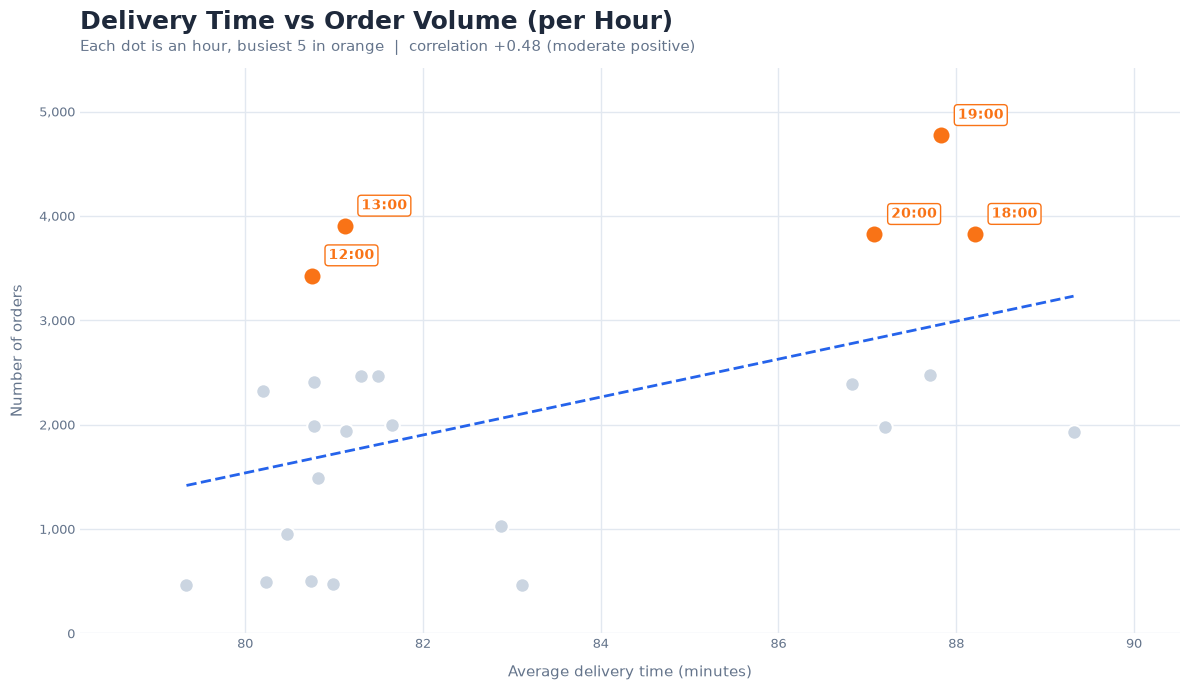

In [6]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TREND = "#2563EB"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

N_PEAK = 5   # how many busiest hours to highlight and label

data  = busy_hours.reset_index(drop=True)
hours = data["order_hour"]
x     = data["avg_del_time"]
y     = data["count"]

thr     = y.nlargest(N_PEAK).min()
is_peak = (y >= thr).values

# Trend line + correlation
slope, intercept = np.polyfit(x, y, 1)
xs   = np.linspace(x.min(), x.max(), 50)
corr = np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor("white")

# Trend line
ax.plot(xs, slope * xs + intercept, color=TREND, linestyle="--",
        linewidth=2, zorder=2)

# Points
ax.scatter(x[~is_peak], y[~is_peak], s=110, color=BASE, edgecolor="white",
           linewidth=1.5, zorder=3)
ax.scatter(x[is_peak], y[is_peak], s=170, color=PEAK, edgecolor="white",
           linewidth=1.5, zorder=4)

# Labels on the busiest hours (white pills so they stay readable)
pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=PEAK, linewidth=1)
for h, xi, yi, p in zip(hours, x, y, is_peak):
    if p:
        ax.annotate(f"{h}:00", (xi, yi), xytext=(12, 12), textcoords="offset points",
                    fontsize=10, fontweight="bold", color=PEAK, bbox=pill, zorder=6)

# Padding so points and labels aren't on the edge
px = (x.max() - x.min()) * 0.12 or 1
py = (y.max() - y.min()) * 0.15 or 1
ax.set_xlim(x.min() - px, x.max() + px)
ax.set_ylim(max(0, y.min() - py), y.max() + py)

# Titles
strength = "strong" if abs(corr) >= 0.7 else "moderate" if abs(corr) >= 0.4 else "weak"
direction = "positive" if corr > 0 else "negative"
ax.set_title("Delivery Time vs Order Volume (per Hour)", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Each dot is an hour, busiest {N_PEAK} in orange  |  "
        f"correlation {corr:+.2f} ({strength} {direction})",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Average delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Number of orders", fontsize=11, color=MUTED, labelpad=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="both", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig("../images/del_time_ord_val.png", dpi=300, bbox_inches="tight")
plt.show()

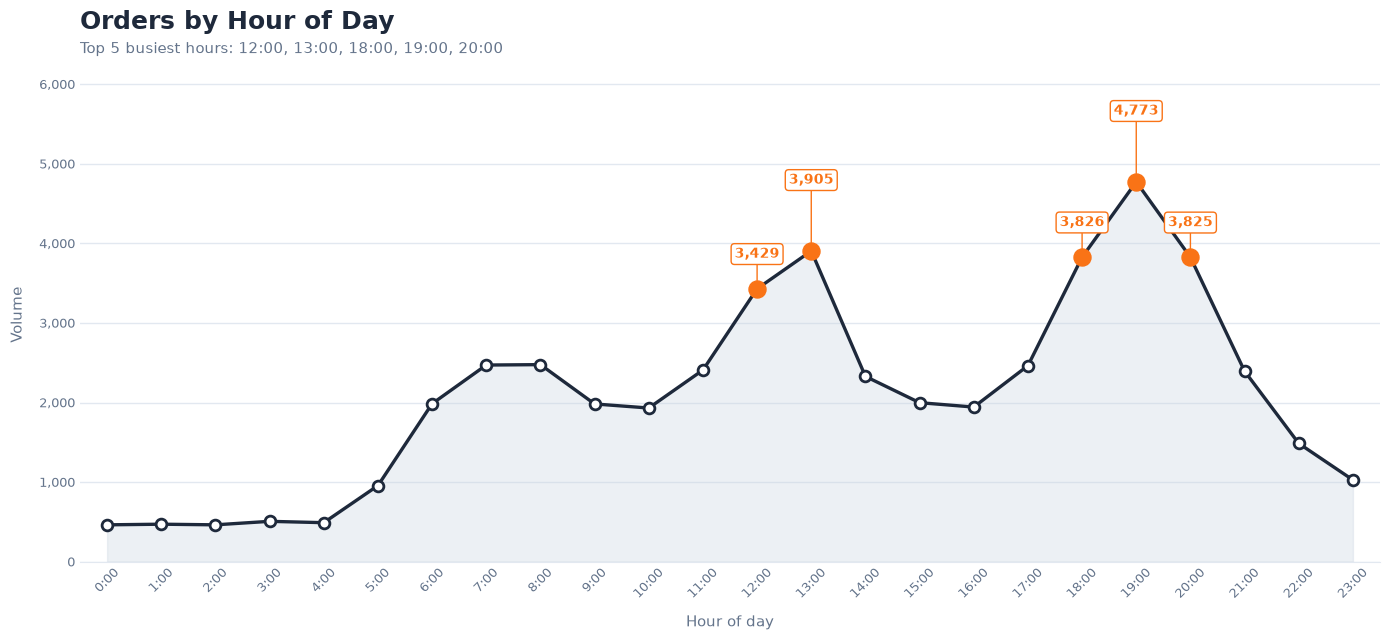

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --- Palette ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
LINE  = "#1E293B"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

N_PEAK = 5   # how many busiest hours to highlight

data   = busy_hours.sort_values("order_hour").reset_index(drop=True)
hours  = data["order_hour"]
counts = data["count"]

thr     = counts.nlargest(N_PEAK).min()
is_peak = (counts >= thr).values

fig, ax = plt.subplots(figsize=(14, 6.5))
fig.patch.set_facecolor("white")

# Area + line + points
ax.fill_between(hours, counts, color=BASE, alpha=0.35, zorder=1)
ax.plot(hours, counts, color=LINE, linewidth=2.4, zorder=3)
ax.scatter(hours[~is_peak], counts[~is_peak], s=60, color="white",
           edgecolor=LINE, linewidth=2, zorder=4)
ax.scatter(hours[is_peak], counts[is_peak], s=150, color=PEAK, zorder=5)

# Labels on peak hours: stagger consecutive hours so they never touch
pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=PEAK, linewidth=1)
level, prev_h = 0, None
for h, c, p in zip(hours, counts, is_peak):
    if not p:
        continue
    level = level + 1 if (prev_h is not None and h - prev_h == 1) else 0
    prev_h = h
    up = 20 + (level % 2) * 26
    ax.annotate(f"{c:,.0f}", (h, c), xytext=(0, up), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold",
                color=PEAK, bbox=pill, zorder=6,
                arrowprops=dict(arrowstyle="-", color=PEAK, linewidth=1,
                                shrinkA=0, shrinkB=6))

# Titles
peak_hours = ", ".join(f"{h}:00" for h in hours[is_peak])
ax.set_title("Orders by Hour of Day", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03, f"Top {N_PEAK} busiest hours: {peak_hours}",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes (starts at 0 because of the area fill)
ax.set_ylim(0, counts.max() * 1.3)
ax.set_xlim(hours.min() - 0.5, hours.max() + 0.5)
ax.set_xticks(np.arange(0, 24))
ax.set_xticklabels([f"{h}:00" for h in range(24)], rotation=45, fontsize=9, color=MUTED)
ax.set_xlabel("Hour of day", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Volume", fontsize=11, color=MUTED, labelpad=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.tick_params(axis="x", length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()
plt.savefig("../images/order_hour_day.png")
plt.show()

In [8]:
# investigating why some during some hours order take more time to arrive

del_avg_time = df.groupby(["order_hour"]).agg(
    count = ("order_id","count"),
    best_time = ("time_taken_min","min"),
    worse_time = ("time_taken_min","max"),
    avg_time = ("time_taken_min","mean"),
    traffic_lvl = ("traffic_lvl_code","median")
).reset_index().round()
del_avg_time

,order_hour,count,best_time,worse_time,avg_time,traffic_lvl
0,0,463,16,180,83.0,1.0
1,1,471,19,180,81.0,1.0
2,2,463,16,180,79.0,1.0
3,3,507,25,180,81.0,1.0
4,4,490,19,180,80.0,1.0
5,5,956,18,180,80.0,1.0
6,6,1985,14,180,81.0,1.0
7,7,2471,14,180,81.0,1.0
8,8,2476,17,180,88.0,2.0
9,9,1982,13,180,87.0,2.0


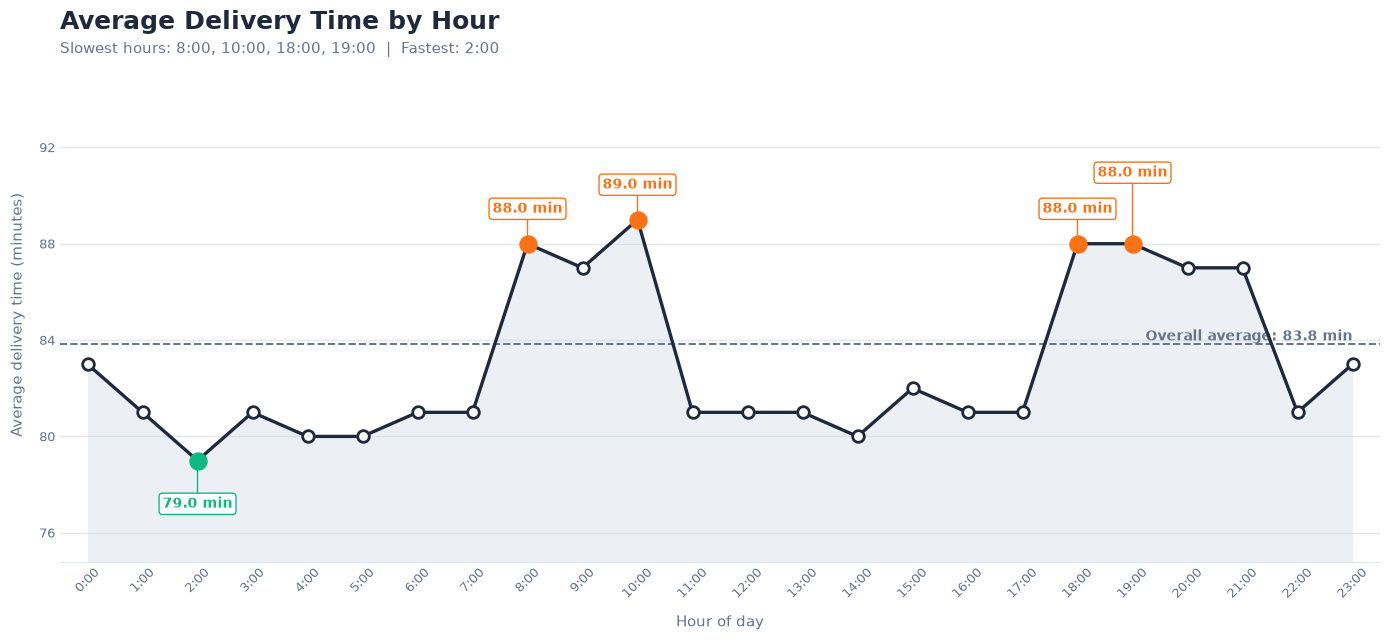

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
GOOD  = "#10B981"
LINE  = "#1E293B"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

N_SLOW = 4   # how many slowest hours to highlight

data  = del_avg_time.sort_values("order_hour").reset_index(drop=True)
hours = data["order_hour"]
vals  = data["avg_time"]

# Overall average, weighted by orders per hour
overall = (vals * data["count"]).sum() / data["count"].sum()

thr     = vals.nlargest(N_SLOW).min()
is_slow = (vals >= thr).values
i_fast  = int(vals.values.argmin())

# Zoom into the real range (extra headroom for the staggered labels)
pad  = (vals.max() - vals.min()) * 0.35 or 1
y_lo = vals.min() - pad * 1.2
y_hi = vals.max() + pad * 1.8

fig, ax = plt.subplots(figsize=(14, 6.5))
fig.patch.set_facecolor("white")
ax.set_ylim(y_lo, y_hi)

# Grey area under the line
ax.fill_between(hours, vals, y_lo, color=BASE, alpha=0.35, linewidth=0, zorder=1)

# Overall average line
ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1.4, zorder=2)
ax.text(hours.iloc[-1], overall, f"Overall average: {overall:.1f} min",
        ha="right", va="bottom", fontsize=10, color=MUTED, fontweight="bold")

# Hourly line + points
ax.plot(hours, vals, color=LINE, linewidth=2.4, zorder=3)
ax.scatter(hours[~is_slow], vals[~is_slow], s=70, color="white",
           edgecolor=LINE, linewidth=2, zorder=4)
ax.scatter(hours[is_slow], vals[is_slow], s=150, color=PEAK, zorder=5)
ax.scatter(hours.iloc[i_fast], vals.iloc[i_fast], s=150, color=GOOD, zorder=5)

# Labels for slow hours: stagger consecutive hours so they never touch
pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=PEAK, linewidth=1)
level, prev_h = 0, None
for h, v, s in zip(hours, vals, is_slow):
    if not s:
        continue
    level = level + 1 if (prev_h is not None and h - prev_h == 1) else 0
    prev_h = h
    up = 20 + (level % 2) * 26          # alternate between two heights
    ax.annotate(f"{v:.1f} min", (h, v), xytext=(0, up), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold",
                color=PEAK, bbox=pill, zorder=6,
                arrowprops=dict(arrowstyle="-", color=PEAK, linewidth=1,
                                shrinkA=0, shrinkB=6))

# Fastest hour label
ax.annotate(f"{vals.iloc[i_fast]:.1f} min", (hours.iloc[i_fast], vals.iloc[i_fast]),
            xytext=(0, -26), textcoords="offset points", ha="center", va="top",
            fontsize=10, fontweight="bold", color=GOOD,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                      edgecolor=GOOD, linewidth=1), zorder=6,
            arrowprops=dict(arrowstyle="-", color=GOOD, linewidth=1,
                            shrinkA=0, shrinkB=6))

# Titles
slow_hours = ", ".join(f"{h}:00" for h in hours[is_slow])
ax.set_title("Average Delivery Time by Hour", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03, f"Slowest hours: {slow_hours}  |  Fastest: {hours.iloc[i_fast]}:00",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlim(hours.min() - 0.5, hours.max() + 0.5)
ax.set_xticks(np.arange(0, 24))
ax.set_xticklabels([f"{h}:00" for h in range(24)], rotation=45, fontsize=9, color=MUTED)
ax.set_xlabel("Hour of day", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Average delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
ax.yaxis.set_major_locator(MaxNLocator(6))
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.tick_params(axis="x", length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()
plt.savefig("../images/avg_del_time_hr")
plt.show()

In [10]:
highest_avg_time = del_avg_time["avg_time"].max()
lowest_avg_time = del_avg_time["avg_time"].min()
range_avg_time = (highest_avg_time-lowest_avg_time).round(2)
print(f"highest time : {highest_avg_time} , lowest time : {lowest_avg_time} , range is : {range_avg_time}")

highest time : 89.0 , lowest time : 79.0 , range is : 10.0


In [11]:
day = ["monday","tuesday","wednesday","thursday","friday","saturday","sunday"]

In [12]:
# busiest days of the week
orders_per_day = df.groupby(["day_of_week"]).agg(
    count = ("order_id","count")
).reset_index()
orders_per_day["day_of_week"] = pd.Categorical(orders_per_day["day_of_week"],categories=day,ordered=True)
orders_per_day  = orders_per_day.sort_values(by="day_of_week")
orders_per_day

,day_of_week,count
1,monday,7160
5,tuesday,7264
6,wednesday,7197
4,thursday,7149
0,friday,7050
2,saturday,6978
3,sunday,7202


In [13]:
week_vol_range = orders_per_day["count"].max() - orders_per_day["count"].min()
print(f"Range of weekly order volume: {week_vol_range:,.0f}")

Range of weekly order volume: 286


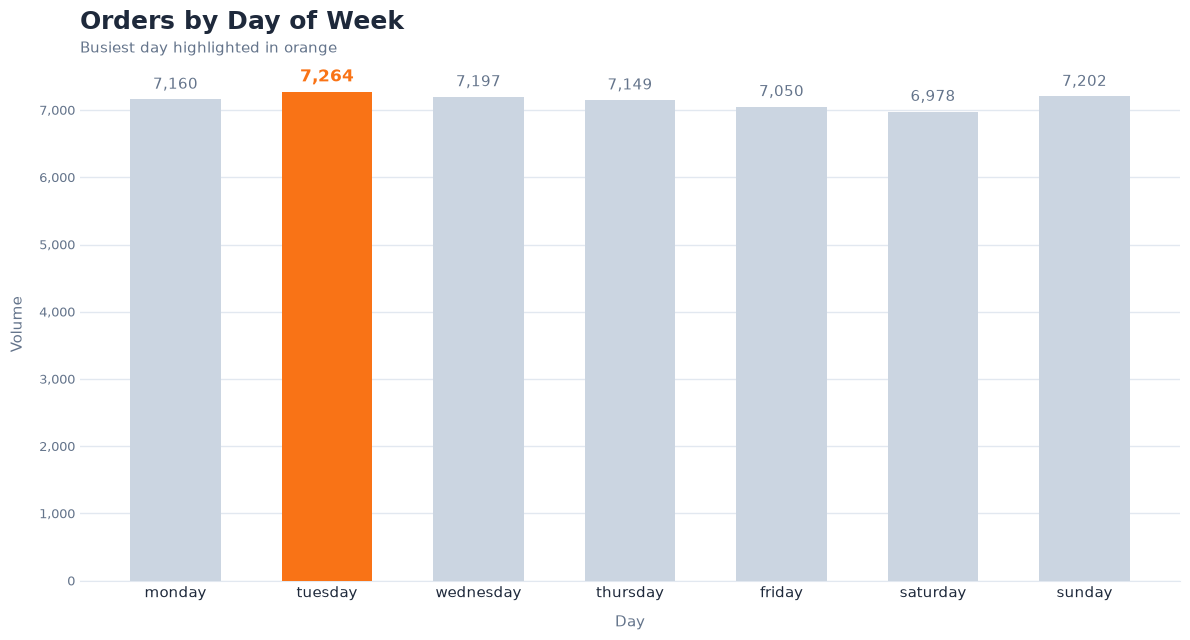

In [14]:

days   = orders_per_day["day_of_week"]
counts = orders_per_day["count"]

# Highlight the busiest day
peak_value = counts.max()
colors = [PEAK if c == peak_value else BASE for c in counts]

fig, ax = plt.subplots(figsize=(12, 6.5))
fig.patch.set_facecolor("white")

bars = ax.bar(days, counts, color=colors, width=0.6, zorder=3)

# Value labels
labels = [f"{c:,.0f}" for c in counts]
text_objs = ax.bar_label(bars, labels=labels, padding=5, fontsize=11, color=MUTED)
for txt, c in zip(text_objs, counts):
    if c == peak_value:
        txt.set_color(PEAK)
        txt.set_fontweight("bold")
        txt.set_fontsize(12)

# Titles
ax.set_title("Orders by Day of Week", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03, "Busiest day highlighted in orange",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Day", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Volume", fontsize=11, color=MUTED, labelpad=10)
ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()
plt.savefig("../images/order_day.png")
plt.show()

In [30]:
# pick up zones that slow us down
pickup_zone_time = df.groupby(["pickup_zone"]).agg(
   count = ("order_id","count"),
   order_time_taken = ("time_taken_min","mean"),
   traffic_lvl = ("traffic_lvl_code","median")
).reset_index().round(2).sort_values(by="order_time_taken",ascending=False)
pickup_zone_time

,pickup_zone,count,order_time_taken,traffic_lvl
0,cbd,10997,93.84,2.0
4,suburban,6461,83.27,1.0
1,commercial,9523,83.26,1.0
3,residential,15786,80.27,1.0
2,industrial,7233,77.91,1.0


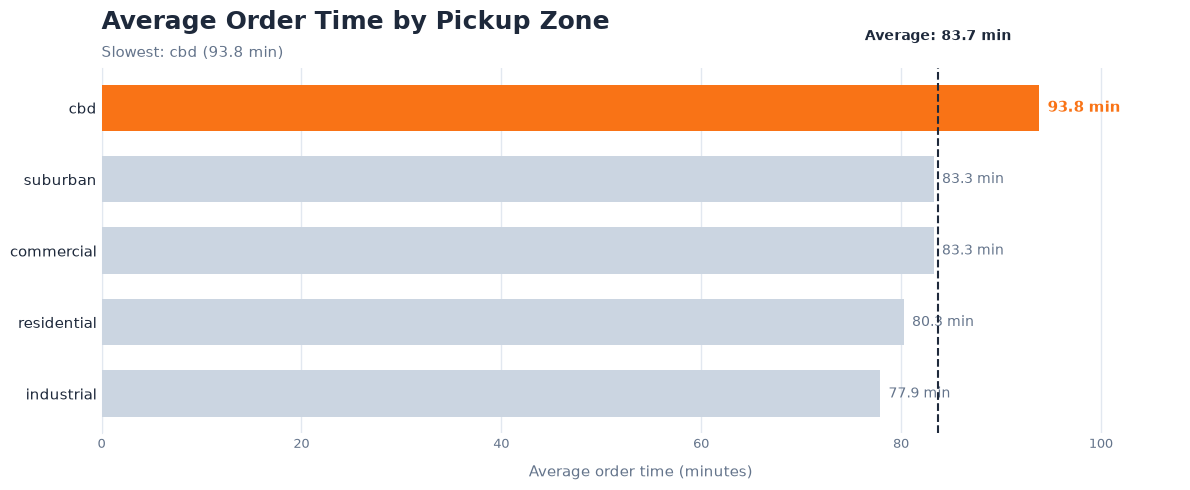

In [16]:
# Sort so the slowest zone is on top
data = (pickup_zone_time
        .sort_values("order_time_taken", ascending=False)
        .reset_index(drop=True))
zones  = data["pickup_zone"]
values = data["order_time_taken"]

avg = values.mean()
slowest_zone, slowest_val = zones.iloc[0], values.iloc[0]

# Highlight the slowest zone
colors = [PEAK if i == 0 else BASE for i in range(len(values))]

fig, ax = plt.subplots(figsize=(12, max(5, len(values) * 0.5)))
fig.patch.set_facecolor("white")

bars = ax.barh(zones, values, color=colors, height=0.65, zorder=3)
ax.invert_yaxis()  # largest at the top

# Value labels
text_objs = ax.bar_label(bars, labels=[f"{v:.1f} min" for v in values],
                         padding=6, fontsize=10, color=MUTED)
text_objs[0].set_color(PEAK)
text_objs[0].set_fontweight("bold")
text_objs[0].set_fontsize(11)

# Average reference line
ax.axvline(avg, color=TEXT, linestyle="--", linewidth=1.5, zorder=4)
ax.text(avg, -0.9, f"Average: {avg:.1f} min", ha="center", va="bottom",
        fontsize=10, color=TEXT, fontweight="bold")

# Titles
ax.set_title("Average Order Time by Pickup Zone", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03, f"Slowest: {slowest_zone} ({slowest_val:.1f} min)",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Average order time (minutes)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, values.max() * 1.15)
ax.tick_params(axis="y", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)

plt.tight_layout()
plt.savefig("../images/avg_order_pick_up_zone.png")
plt.show()

In [17]:
# Which pickup-to-dropoff zone pairs take longest?
pickup_dropoff = df.groupby(["pickup_zone","dropoff_zone"]).agg(
    count = ("order_id","count"),
    avg_time = ("time_taken_min","mean")
).reset_index().round(2).sort_values(by="avg_time",ascending=False)
pickup_dropoff

,pickup_zone,dropoff_zone,count,avg_time
4,cbd,suburban,1656,94.45
1,cbd,commercial,2337,93.87
3,cbd,residential,3587,93.70
2,cbd,industrial,1447,93.69
0,cbd,cbd,1970,93.62
7,commercial,industrial,1286,84.80
23,suburban,residential,2063,84.14
6,commercial,commercial,2044,83.65
24,suburban,suburban,906,83.30
22,suburban,industrial,840,83.25


In [18]:
# How should we change staffing or delivery radius in rain, fog and storms?
weather_conditions = df.groupby("weather").agg(
    count = ("order_id","count"),
    max_time = ("time_taken_min","max"),
    min_time = ("time_taken_min","min"),
    avg_time = ("time_taken_min","mean"),
    distance_km = ("road_distance_km","mean")
).reset_index().round(2).sort_values(by="avg_time",ascending=False)
weather_conditions

,weather,count,max_time,min_time,avg_time,distance_km
4,storm,2437,180,24,114.45,26.62
3,rain,9073,180,17,98.86,26.19
2,fog,3413,180,12,84.15,26.13
1,cloudy,11085,180,12,79.02,26.28
0,clear,23992,180,10,77.30,26.13


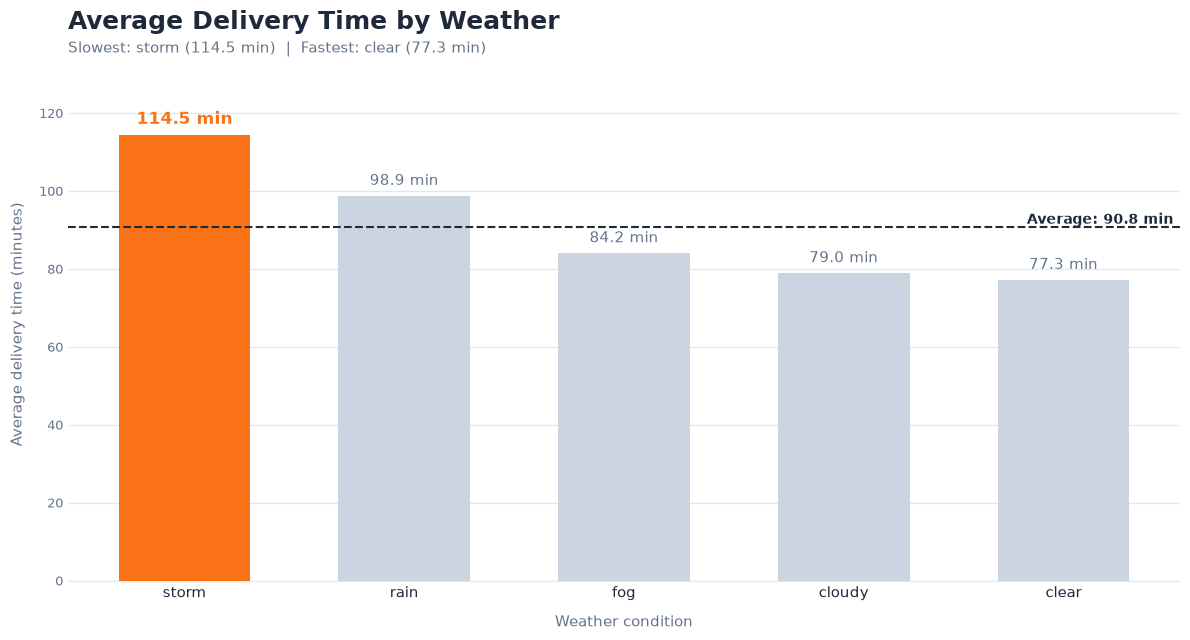

In [19]:
# Sort so the slowest condition comes first
data = (weather_conditions
        .sort_values("avg_time", ascending=False)
        .reset_index(drop=True))
weather = data["weather"]
values  = data["avg_time"]

avg = values.mean()
slowest, slowest_val = weather.iloc[0], values.iloc[0]
fastest, fastest_val = weather.iloc[-1], values.iloc[-1]

# Highlight the slowest condition
colors = [PEAK if i == 0 else BASE for i in range(len(values))]

fig, ax = plt.subplots(figsize=(12, 6.5))
fig.patch.set_facecolor("white")

bars = ax.bar(weather, values, color=colors, width=0.6, zorder=3)

# Value labels
text_objs = ax.bar_label(bars, labels=[f"{v:.1f} min" for v in values],
                         padding=5, fontsize=11, color=MUTED)
text_objs[0].set_color(PEAK)
text_objs[0].set_fontweight("bold")
text_objs[0].set_fontsize(12)

# Average reference line
ax.axhline(avg, color=TEXT, linestyle="--", linewidth=1.5, zorder=4)
ax.text(len(values) - 0.5, avg, f"Average: {avg:.1f} min", ha="right", va="bottom",
        fontsize=10, color=TEXT, fontweight="bold")

# Titles
ax.set_title("Average Delivery Time by Weather", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Slowest: {slowest} ({slowest_val:.1f} min)  |  Fastest: {fastest} ({fastest_val:.1f} min)",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Weather condition", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Average delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, values.max() * 1.15)
ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()
plt.savefig("../images/avg_del_time_weather.png")
plt.show()

In [20]:
# How much time do we lose to traffic?
time_loss_traffic = df.groupby("traffic_level").agg(
    count = ("order_id","count"),
    time_taken = ("time_taken_min","mean")
).reset_index().round().sort_values(by="time_taken",ascending=False)
time_loss_traffic

,traffic_level,count,time_taken
3,severe,524,134.0
0,high,3744,112.0
2,moderate,13165,92.0
1,low,32567,76.0


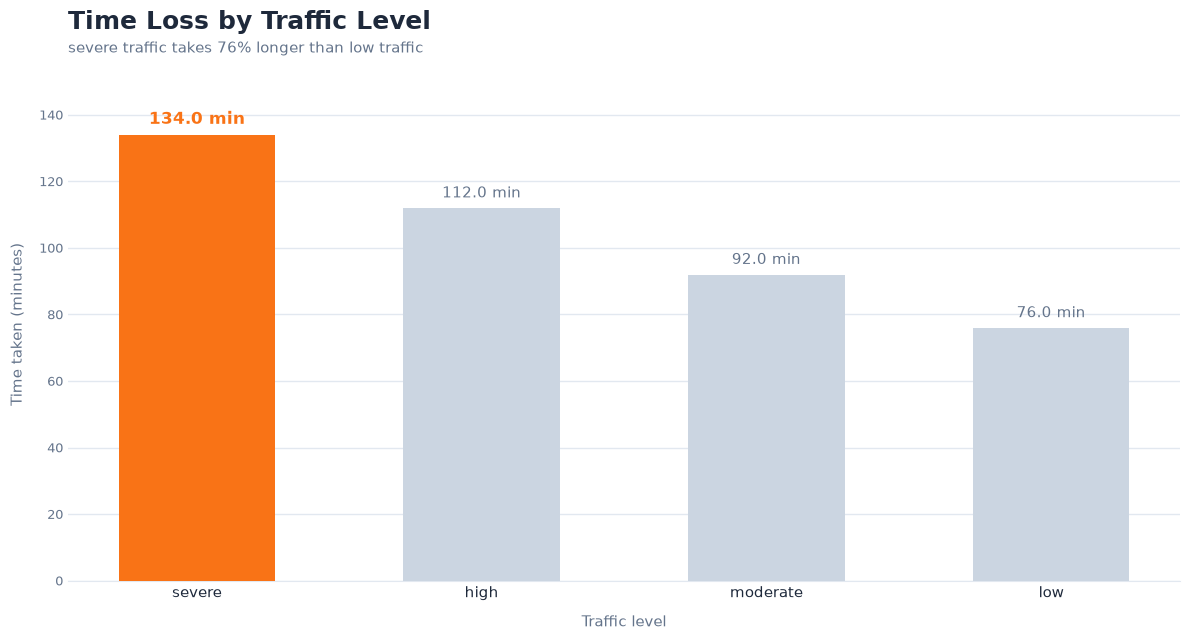

In [21]:
data = time_loss_traffic.copy()

# Natural order of traffic levels (adjust names to match your data)
order = ["Low", "Medium", "High", "Jam"]
if set(order) == set(data["traffic_level"].str.title()):
    data["traffic_level"] = data["traffic_level"].str.title()
    data = data.set_index("traffic_level").loc[order].reset_index()

levels = data["traffic_level"]
values = data["time_taken"]

worst_i = values.values.argmax()
best_i  = values.values.argmin()
worst, worst_val = levels.iloc[worst_i], values.iloc[worst_i]
best,  best_val  = levels.iloc[best_i],  values.iloc[best_i]
extra_pct = (worst_val - best_val) / best_val * 100

# Highlight the worst level
colors = [PEAK if i == worst_i else BASE for i in range(len(values))]

fig, ax = plt.subplots(figsize=(12, 6.5))
fig.patch.set_facecolor("white")

bars = ax.bar(levels, values, color=colors, width=0.55, zorder=3)

# Value labels
text_objs = ax.bar_label(bars, labels=[f"{v:,.1f} min" for v in values],
                         padding=5, fontsize=11, color=MUTED)
text_objs[worst_i].set_color(PEAK)
text_objs[worst_i].set_fontweight("bold")
text_objs[worst_i].set_fontsize(12)

# Titles
ax.set_title("Time Loss by Traffic Level", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"{worst} traffic takes {extra_pct:.0f}% longer than {best} traffic",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Traffic level", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Time taken (minutes)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, values.max() * 1.15)
ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()
plt.savefig("../images/time_loss_traffic.png")
plt.show()

In [22]:
# Do more traffic signals on a route add meaningful delay?
traffic_signals = df.groupby("number_of_signals").agg(
    count = ("order_id","count"),
    time_taken = ("time_taken_min","mean")
).reset_index().round(2).sort_values(by="time_taken",ascending=False)
traffic_signals

,number_of_signals,count,time_taken
16,18,2192,94.68
15,17,2190,94.45
14,16,2254,94.35
13,15,2153,92.45
12,14,4145,88.78
0,2,1260,84.21
11,13,1903,83.96
9,11,1924,83.23
1,3,1298,83.18
10,12,1861,83.12


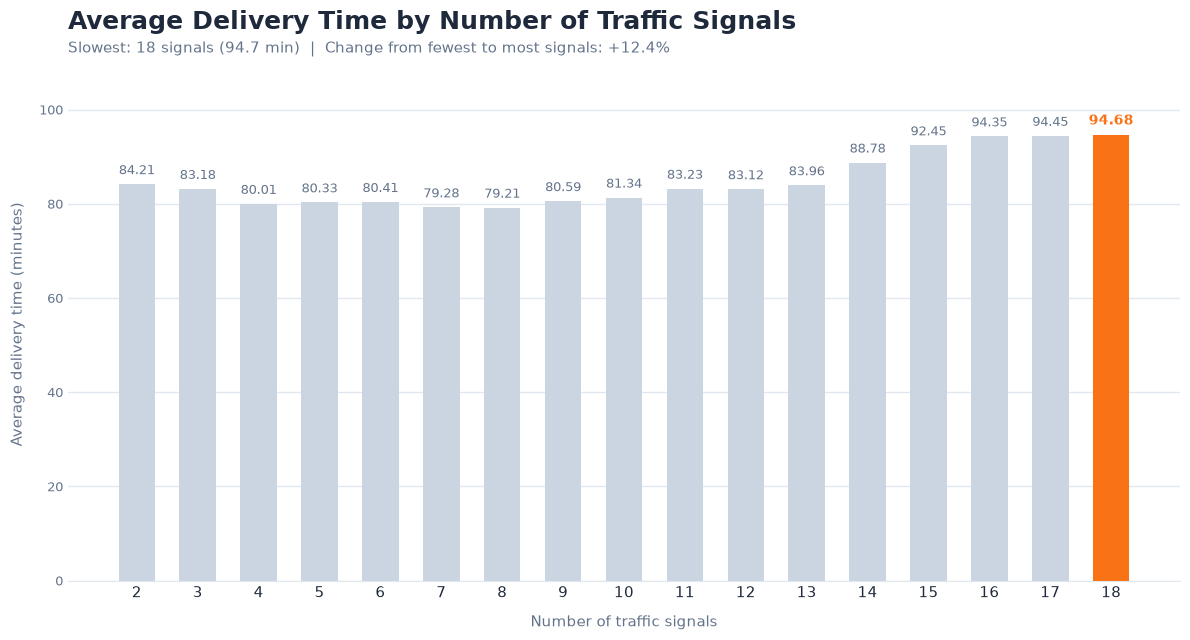

In [23]:
# Natural order: fewest signals -> most signals
data = (traffic_signals
        .sort_values("number_of_signals")
        .reset_index(drop=True))
signals = data["number_of_signals"]
values  = data["time_taken"]

worst_i = values.values.argmax()
worst_signals, worst_val = signals.iloc[worst_i], values.iloc[worst_i]

first_val, last_val = values.iloc[0], values.iloc[-1]
change = (last_val - first_val) / first_val * 100

# Highlight the slowest bar
colors = [PEAK if i == worst_i else BASE for i in range(len(values))]

fig, ax = plt.subplots(figsize=(12, 6.5))
fig.patch.set_facecolor("white")

# Plot on positions 0..n-1 so bars stay evenly spaced
x = np.arange(len(values))
bars = ax.bar(x, values, color=colors, width=0.6, zorder=3)

# Value labels
label_size = 11 if len(values) <= 12 else 9
text_objs = ax.bar_label(bars, labels=[f"{v:.2f}" for v in values],
                         padding=5, fontsize=label_size, color=MUTED)
text_objs[worst_i].set_color(PEAK)
text_objs[worst_i].set_fontweight("bold")
text_objs[worst_i].set_fontsize(label_size + 1)

# Titles
ax.set_title("Average Delivery Time by Number of Traffic Signals", loc="left",
             fontsize=18, fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Slowest: {worst_signals} signals ({worst_val:.1f} min)  |  "
        f"Change from fewest to most signals: {change:+.1f}%",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xticks(x)
ax.set_xticklabels(signals.astype(int), fontsize=11, color=TEXT)
ax.set_xlabel("Number of traffic signals", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Average delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylim(0, values.max() * 1.15)
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()
plt.savefig("../images/avg_del_time_traffic_signals.png")
plt.show()

In [24]:
# How many orders are delivered per hour at peak, and how does speed change
#      as volume rises?
speed_per_hour = df.groupby(["order_hour"]).agg(
    volume = ("order_id","size"),
    del_avg_time = ("time_taken_min","median"),
    avg_traffic_lvl = ("traffic_lvl_code","median"),
    avg_speed = ("average_speed_kmph","mean")
).reset_index().round(2).sort_values(by="del_avg_time",ascending=False)
speed_per_hour

,order_hour,volume,del_avg_time,avg_traffic_lvl,avg_speed
10,10,1931,83.0,2.0,29.51
18,18,3826,82.0,2.0,29.73
8,8,2476,81.0,2.0,29.66
9,9,1982,81.0,2.0,29.59
20,20,3825,81.0,2.0,29.65
19,19,4773,81.0,2.0,29.83
21,21,2394,80.0,2.0,29.66
1,1,471,77.0,1.0,33.81
23,23,1027,77.0,1.0,32.81
11,11,2408,76.0,1.0,33.34


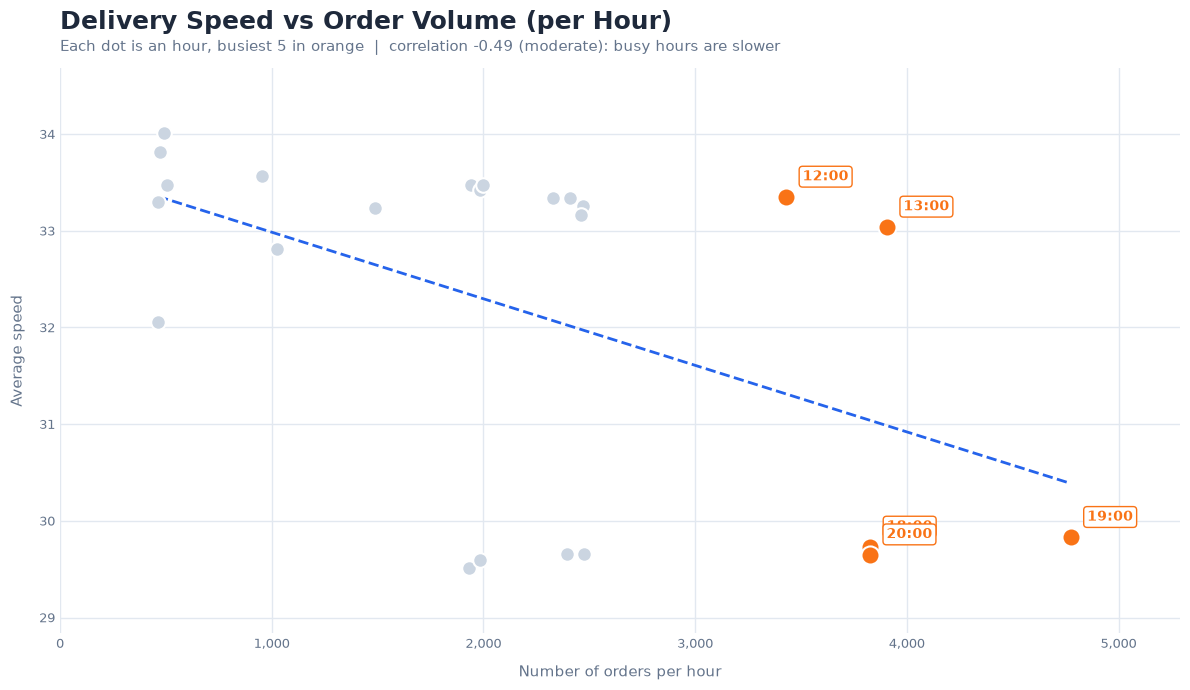

In [31]:
N_PEAK = 5   # how many busiest hours to highlight and label

data  = speed_per_hour.reset_index(drop=True)
hours = data["order_hour"]
x     = data["volume"]
y     = data["avg_speed"]

thr     = x.nlargest(N_PEAK).min()
is_peak = (x >= thr).values

# Trend line + correlation
slope, intercept = np.polyfit(x, y, 1)
xs   = np.linspace(x.min(), x.max(), 50)
corr = np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor("white")

# Trend line
ax.plot(xs, slope * xs + intercept, color=TREND, linestyle="--",
        linewidth=2, zorder=2)

# Points
ax.scatter(x[~is_peak], y[~is_peak], s=110, color=BASE, edgecolor="white",
           linewidth=1.5, zorder=3)
ax.scatter(x[is_peak], y[is_peak], s=170, color=PEAK, edgecolor="white",
           linewidth=1.5, zorder=4)

# Labels on the busiest hours (white pills so they stay readable)
pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=PEAK, linewidth=1)
for h, xi, yi, p in zip(hours, x, y, is_peak):
    if p:
        ax.annotate(f"{h}:00", (xi, yi), xytext=(12, 12), textcoords="offset points",
                    fontsize=10, fontweight="bold", color=PEAK, bbox=pill, zorder=6)

# Padding so points and labels aren't on the edge
px = (x.max() - x.min()) * 0.12 or 1
py = (y.max() - y.min()) * 0.15 or 1
ax.set_xlim(max(0, x.min() - px), x.max() + px)
ax.set_ylim(y.min() - py, y.max() + py)

# Titles (for speed, higher is better, so a negative correlation means busy hours are slower)
strength = "strong" if abs(corr) >= 0.7 else "moderate" if abs(corr) >= 0.4 else "weak"
meaning  = ("busy hours are slower" if corr < 0 else "busy hours are faster") \
           if abs(corr) >= 0.4 else "little link between volume and speed"
ax.set_title("Delivery Speed vs Order Volume (per Hour)", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Each dot is an hour, busiest {N_PEAK} in orange  |  "
        f"correlation {corr:+.2f} ({strength}): {meaning}",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Number of orders per hour", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Average speed", fontsize=11, color=MUTED, labelpad=10)   # add the unit, e.g. (km/h)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="both", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig("../images/del_speed_ord_vol.png", dpi=300, bbox_inches="tight")
plt.show()

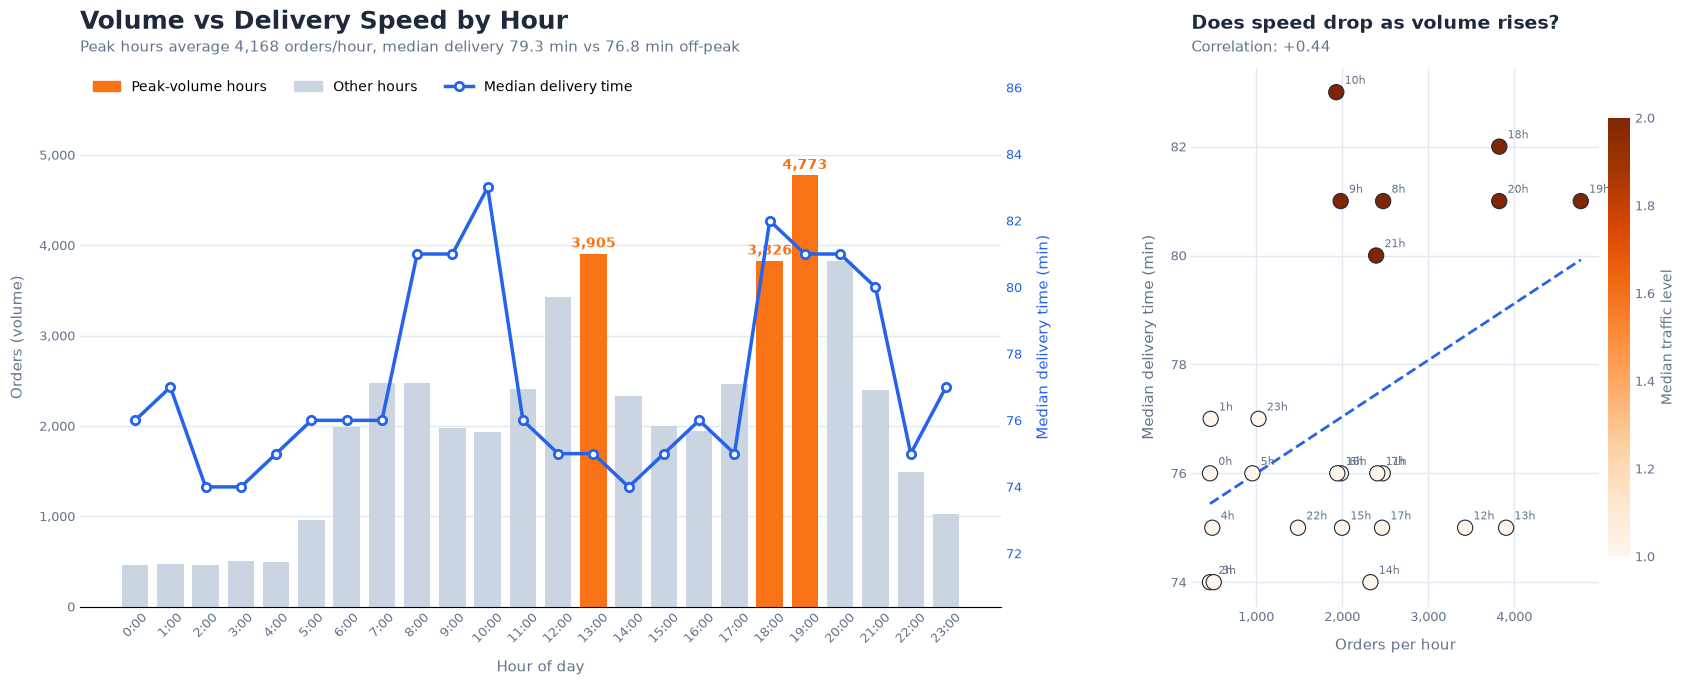

In [26]:
BASE   = "#CBD5E1"
PEAK   = "#F97316"
TREND  = "#2563EB"
TEXT   = "#1E293B"
MUTED  = "#64748B"
GRID   = "#E2E8F0"
# Back to hour order (your table is sorted by time, which is wrong for plotting)
data = speed_per_hour.sort_values("order_hour").reset_index(drop=True)
hours   = data["order_hour"]
vol     = data["volume"]
time    = data["del_avg_time"]
traffic = data["avg_traffic_lvl"]

# Peak hours = top 3 by volume
threshold = vol.nlargest(3).min()
is_peak = vol >= threshold
bar_colors = [PEAK if p else BASE for p in is_peak]

peak_avg_vol  = vol[is_peak].mean()
peak_avg_time = time[is_peak].mean()
off_avg_time  = time[~is_peak].mean()
corr = np.corrcoef(vol, time)[0, 1]

fig = plt.figure(figsize=(20, 7))
gs = fig.add_gridspec(1, 2, width_ratios=[2.1, 1], wspace=0.28)
fig.patch.set_facecolor("white")

# ---------- Left: volume (bars) + delivery time (line) ----------
ax1 = fig.add_subplot(gs[0])
ax2 = ax1.twinx()

bars = ax1.bar(hours, vol, color=bar_colors, width=0.75, zorder=2)
for h, v, p in zip(hours, vol, is_peak):
    if p:
        ax1.text(h, v + vol.max() * 0.015, f"{v:,.0f}", ha="center",
                 fontsize=10, fontweight="bold", color=PEAK)

ax2.plot(hours, time, color=TREND, linewidth=2.5, marker="o", markersize=6,
         markerfacecolor="white", markeredgewidth=2, zorder=5)
pad = (time.max() - time.min()) * 0.4 or 1
ax2.set_ylim(time.min() - pad, time.max() + pad)

ax1.set_ylim(0, vol.max() * 1.25)
ax1.set_xticks(np.arange(0, 24))
ax1.set_xticklabels([f"{h}:00" for h in range(24)], rotation=45, fontsize=9, color=MUTED)
ax1.set_xlabel("Hour of day", fontsize=11, color=MUTED, labelpad=10)
ax1.set_ylabel("Orders (volume)", fontsize=11, color=MUTED, labelpad=10)
ax2.set_ylabel("Median delivery time (min)", fontsize=11, color=TREND, labelpad=10)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax1.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax1.tick_params(axis="x", length=0)
ax2.tick_params(axis="y", labelsize=9, colors=TREND, length=0)

ax1.set_axisbelow(True)
ax1.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for a in (ax1, ax2):
    for side in ["top", "right", "left"]:
        a.spines[side].set_visible(False)
ax1.spines["bottom"].set_color(GRID)

ax1.legend(handles=[
    Patch(color=PEAK, label="Peak-volume hours"),
    Patch(color=BASE, label="Other hours"),
    Line2D([0], [0], color=TREND, marker="o", markerfacecolor="white",
           markeredgewidth=2, linewidth=2.5, label="Median delivery time"),
], frameon=False, loc="upper left", fontsize=10, ncol=3)

ax1.set_title("Volume vs Delivery Speed by Hour", loc="left", fontsize=18,
              fontweight="bold", color=TEXT, pad=28)
ax1.text(0, 1.03,
         f"Peak hours average {peak_avg_vol:,.0f} orders/hour, "
         f"median delivery {peak_avg_time:.1f} min vs {off_avg_time:.1f} min off-peak",
         transform=ax1.transAxes, fontsize=11, color=MUTED)

# ---------- Right: does speed change as volume rises? ----------
ax3 = fig.add_subplot(gs[1])
sc = ax3.scatter(vol, time, c=traffic, cmap="Oranges", s=120,
                 edgecolor=TEXT, linewidth=0.8, zorder=3)

slope, intercept = np.polyfit(vol, time, 1)
xs = np.linspace(vol.min(), vol.max(), 50)
ax3.plot(xs, slope * xs + intercept, color=TREND, linestyle="--", linewidth=2, zorder=2)

for h, v, t in zip(hours, vol, time):
    ax3.annotate(f"{h}h", (v, t), xytext=(6, 6), textcoords="offset points",
                 fontsize=8, color=MUTED)

cbar = fig.colorbar(sc, ax=ax3, pad=0.02, fraction=0.05)
cbar.set_label("Median traffic level", fontsize=10, color=MUTED)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=9, colors=MUTED, length=0)

ax3.set_xlabel("Orders per hour", fontsize=11, color=MUTED, labelpad=10)
ax3.set_ylabel("Median delivery time (min)", fontsize=11, color=MUTED, labelpad=10)
ax3.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax3.tick_params(labelsize=9, colors=MUTED, length=0)
ax3.set_axisbelow(True)
ax3.grid(color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left", "bottom"]:
    ax3.spines[side].set_visible(False)

ax3.set_title("Does speed drop as volume rises?", loc="left", fontsize=14,
              fontweight="bold", color=TEXT, pad=28)
ax3.text(0, 1.03, f"Correlation: {corr:+.2f}", transform=ax3.transAxes,
         fontsize=11, color=MUTED)

plt.show()

In [27]:
df["traffic_level"].value_counts()

traffic_level
low         32567
moderate    13165
high         3744
severe        524
Name: count, dtype: int64

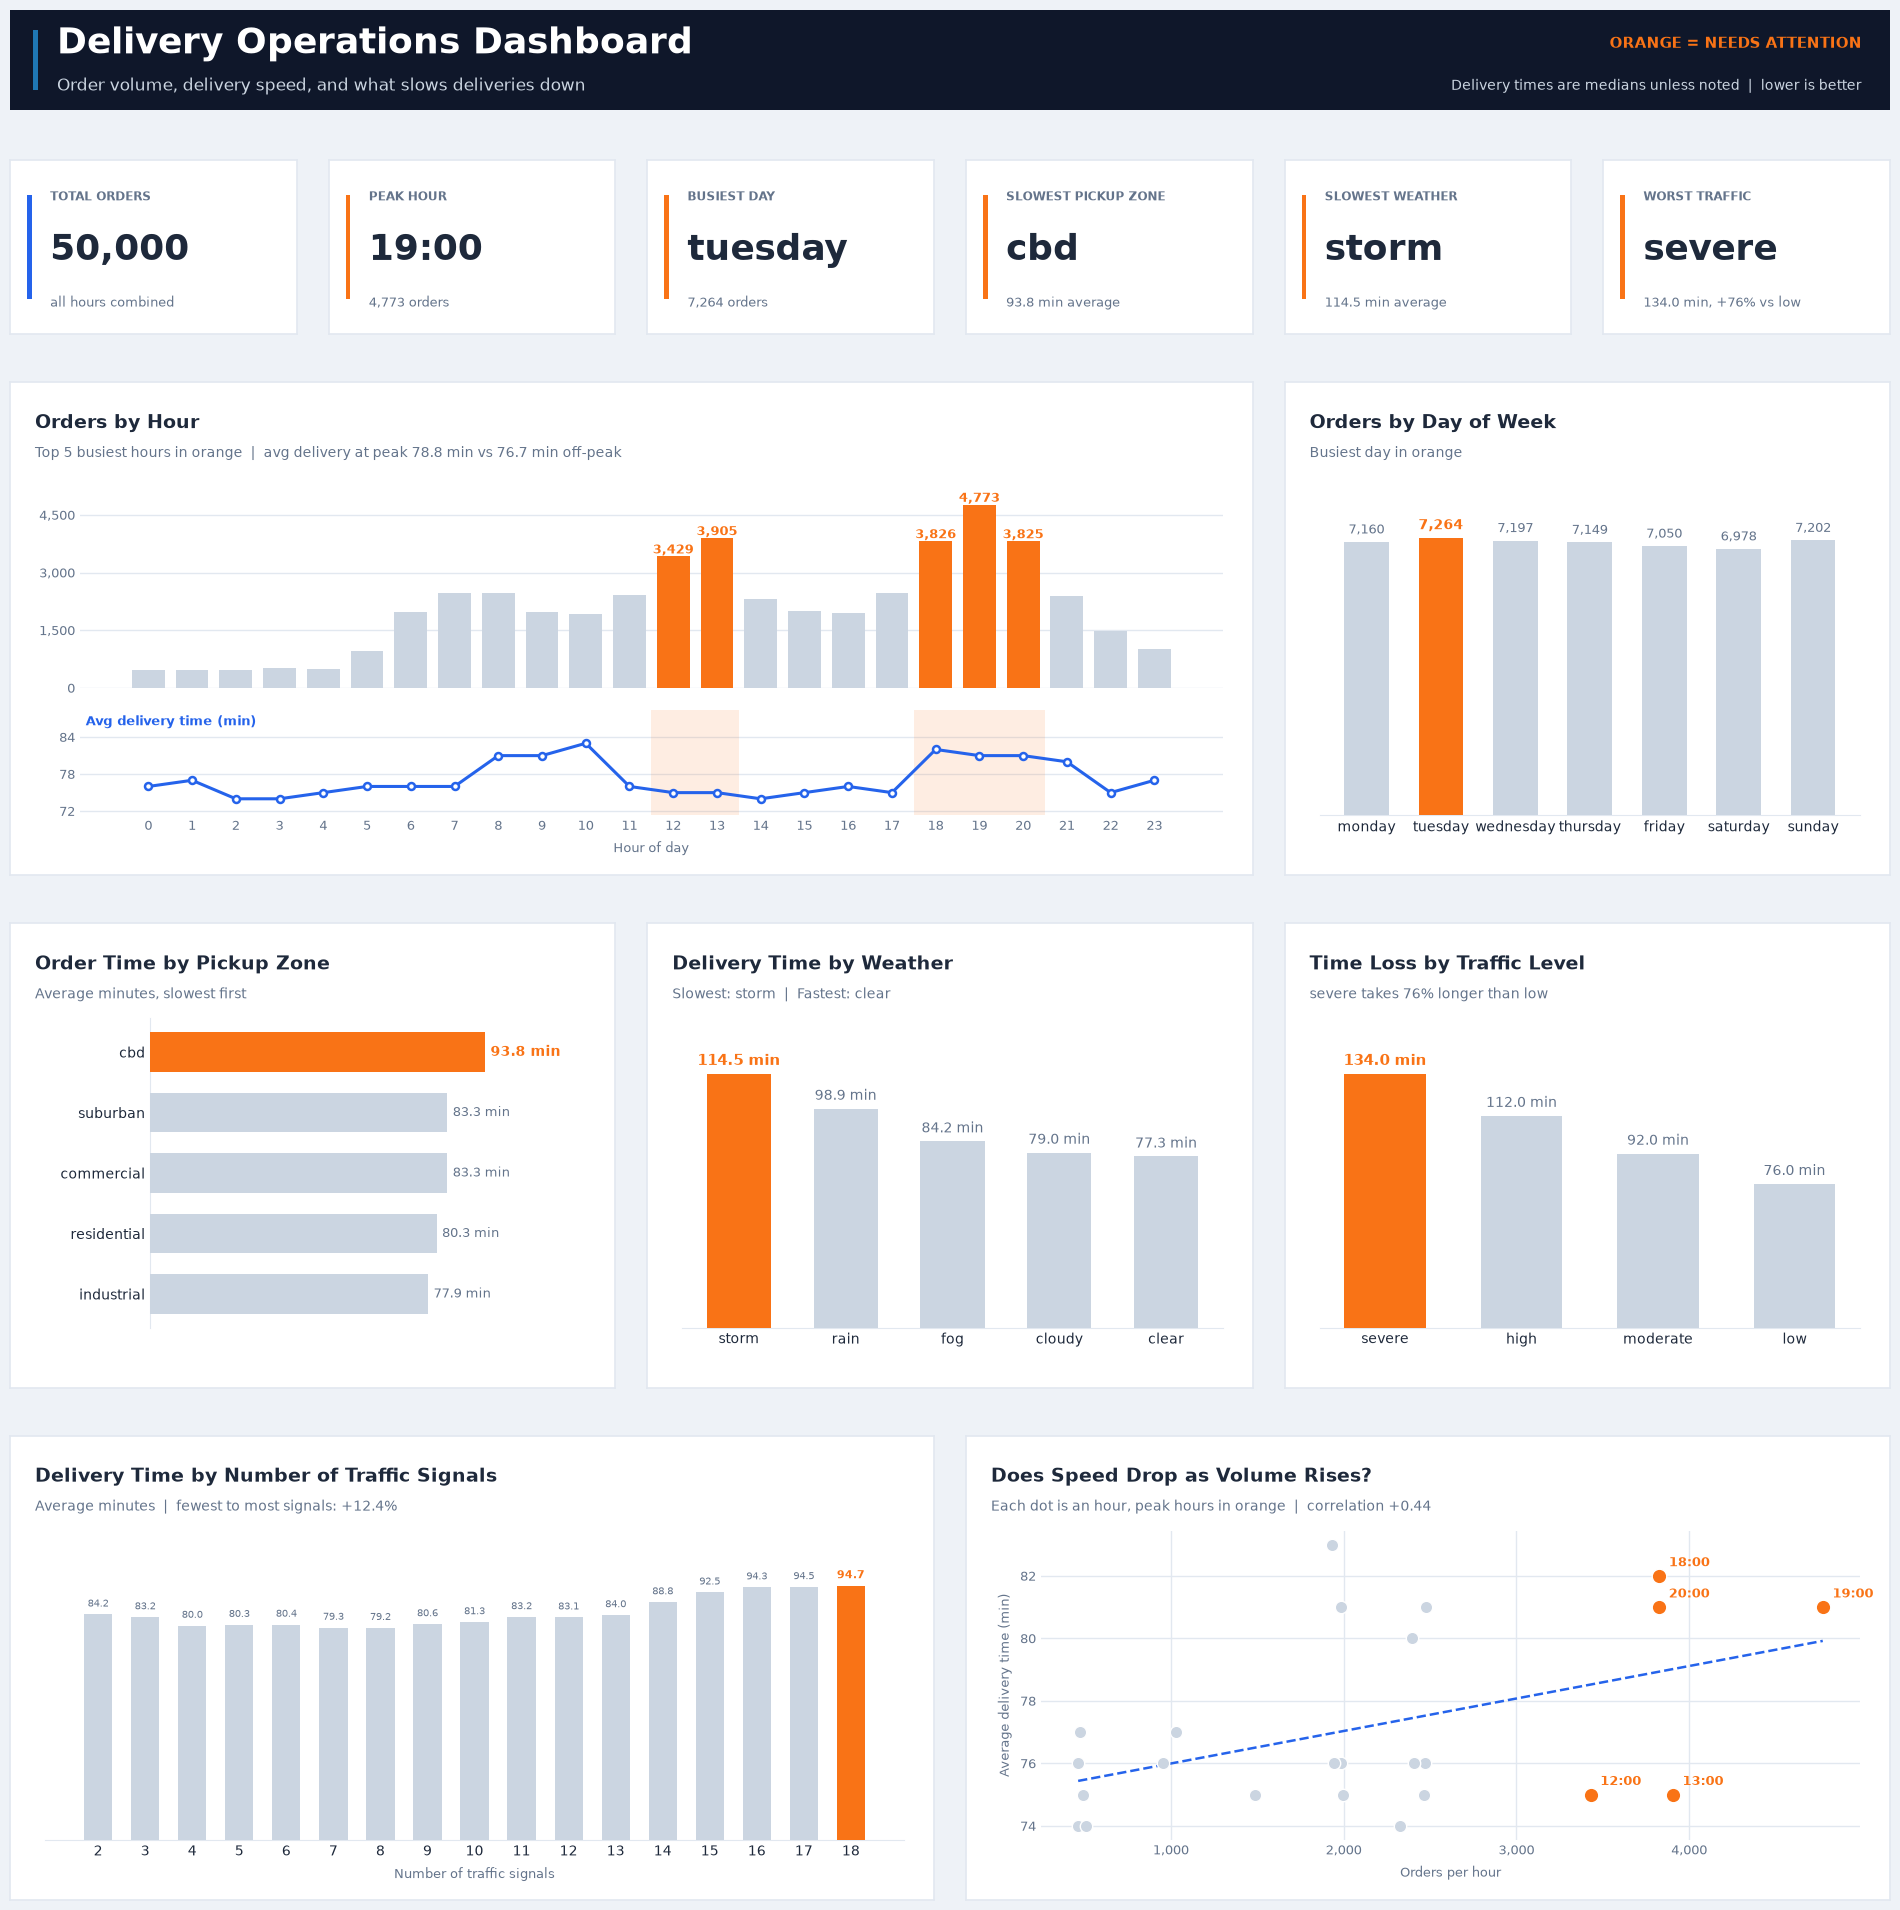

In [28]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib.patches import Rectangle

# ---------------- Palette ----------------
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TREND = "#2563EB"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"
BG    = "#EEF2F7"
CARD  = "#FFFFFF"
DARK  = "#0F172A"

N_PEAK  = 5
fmt_int = FuncFormatter(lambda v, _: f"{v:,.0f}")

# ---------------- Data prep ----------------
sph = speed_per_hour.sort_values("order_hour").reset_index(drop=True)
hours, vol, time = sph["order_hour"], sph["volume"], sph["del_avg_time"]
thr     = vol.nlargest(N_PEAK).min()
is_peak = (vol >= thr).values
corr    = np.corrcoef(vol, time)[0, 1]

days  = orders_per_day["day_of_week"].astype(str)
d_cnt = orders_per_day["count"]

zones = pickup_zone_time.sort_values("order_time_taken", ascending=False).reset_index(drop=True)
wx    = weather_conditions.sort_values("avg_time", ascending=False).reset_index(drop=True)

tl = time_loss_traffic.copy()
order = ["Low", "Medium", "High", "Jam"]
if set(order) == set(tl["traffic_level"].str.title()):
    tl["traffic_level"] = tl["traffic_level"].str.title()
    tl = tl.set_index("traffic_level").loc[order].reset_index()
tl_vals = tl["time_taken"]
tl_w, tl_b = int(tl_vals.values.argmax()), int(tl_vals.values.argmin())
tl_extra = (tl_vals.iloc[tl_w] - tl_vals.iloc[tl_b]) / tl_vals.iloc[tl_b] * 100

sig = traffic_signals.sort_values("number_of_signals").reset_index(drop=True)

# ---------------- Figure + grid ----------------
W, H = 20, 20
fig = plt.figure(figsize=(W, H))
fig.patch.set_facecolor(BG)
gs = fig.add_gridspec(4, 12, height_ratios=[1.2, 3.4, 3.2, 3.2],
                      hspace=0.12, wspace=0.25,
                      left=0.03, right=0.97, top=0.90, bottom=0.03)

# ---------------- Helpers ----------------
def card(ax, grid=None):
    """Style the plotting area: no spines, light grid on the chosen axis."""
    ax.set_facecolor(CARD)
    ax.set_axisbelow(True)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=1, zorder=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0, labelsize=9, colors=MUTED)

def panel(spec, l=0.55, b=0.6, r=0.3, t=0.95):
    """White card filling a grid cell, with the chart placed inside it.
    l, b, r, t = inner margins in inches (left, bottom, right, top)."""
    box = spec.get_position(fig)
    bg = fig.add_axes(box.bounds, zorder=-1)
    bg.set_facecolor(CARD)
    bg.set_xticks([]); bg.set_yticks([])
    for s in bg.spines.values():
        s.set_color(GRID); s.set_linewidth(1.2)
    ax = fig.add_axes([box.x0 + l / W, box.y0 + b / H,
                       box.width - (l + r) / W, box.height - (b + t) / H])
    ax._l = l
    card(ax)
    return ax

def heading(ax, title, sub=None, sub_color=MUTED):
    """Title + subtitle, left-aligned to the card edge."""
    x = -(ax._l - 0.25) / (ax.get_position().width * W)
    ax.annotate(title, xy=(x, 1), xycoords="axes fraction",
                xytext=(0, 32 if sub else 14), textcoords="offset points",
                fontsize=13.5, fontweight="bold", color=TEXT, ha="left", va="bottom")
    if sub:
        ax.annotate(sub, xy=(x, 1), xycoords="axes fraction",
                    xytext=(0, 12), textcoords="offset points",
                    fontsize=10, color=sub_color, ha="left", va="bottom")

def bar_panel(ax, labels, values, hi, fmt="{:.1f} min", horizontal=False, fs=10):
    """Bars with direct labels, one highlighted bar, no value axis."""
    labels = list(labels)
    colors = [PEAK if i == hi else BASE for i in range(len(values))]
    if horizontal:
        bars = ax.barh(labels, values, color=colors, height=0.65, zorder=3)
        ax.invert_yaxis()
        ax.set_xlim(0, values.max() * 1.3)
        ax.xaxis.set_visible(False)
        ax.spines["left"].set_visible(True)
        ax.spines["left"].set_color(GRID)
        ax.tick_params(axis="y", labelsize=10, colors=TEXT)
    else:
        bars = ax.bar(labels, values, color=colors, width=0.6, zorder=3)
        ax.set_ylim(0, values.max() * 1.22)
        ax.yaxis.set_visible(False)
        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_color(GRID)
        ax.tick_params(axis="x", labelsize=10, colors=TEXT)
    t = ax.bar_label(bars, labels=[fmt.format(v) for v in values],
                     padding=4, fontsize=fs, color=MUTED)
    t[hi].set_color(PEAK)
    t[hi].set_fontweight("bold")
    t[hi].set_fontsize(fs + 1)

def kpi_card(spec, label, value, sub, accent=PEAK):
    """KPI card: label top, value middle, subtext bottom, accent bar on the left."""
    box = spec.get_position(fig)
    ax = fig.add_axes(box.bounds)
    ax.set_facecolor(CARD)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color(GRID); s.set_linewidth(1.2)
    ax.add_patch(Rectangle((0.06, 0.2), 0.016, 0.6, transform=ax.transAxes,
                           color=accent, linewidth=0))
    value = str(value)
    n = len(value)
    size = 26 if n <= 7 else 20 if n <= 10 else 15 if n <= 14 else 12   # shrink long names
    ax.text(0.14, 0.82, label.upper(), transform=ax.transAxes,
            fontsize=8.5, color=MUTED, va="top", fontweight="bold")
    ax.text(0.14, 0.48, value, transform=ax.transAxes,
            fontsize=size, fontweight="bold", color=TEXT, va="center")
    ax.text(0.14, 0.14, sub, transform=ax.transAxes,
            fontsize=9.5, color=MUTED, va="bottom")

# ---------------- Header banner ----------------
hdr = fig.add_axes([0.03, 0.925, 0.94, 0.05])
hdr.set_facecolor(DARK)
hdr.set_xticks([]); hdr.set_yticks([])
for s in hdr.spines.values():
    s.set_visible(False)
hdr.add_patch(Rectangle((0.012, 0.2), 0.003, 0.6, transform=hdr.transAxes,linewidth=0))
hdr.text(0.025, 0.66, "Delivery Operations Dashboard", transform=hdr.transAxes,
         fontsize=26, fontweight="bold", color="white", va="center")
hdr.text(0.025, 0.24, "Order volume, delivery speed, and what slows deliveries down",
         transform=hdr.transAxes, fontsize=12, color=BASE, va="center")
hdr.text(0.985, 0.66, "ORANGE = NEEDS ATTENTION", transform=hdr.transAxes,
         fontsize=10.5, fontweight="bold", color=PEAK, ha="right", va="center")
hdr.text(0.985, 0.24, "Delivery times are medians unless noted  |  lower is better",
         transform=hdr.transAxes, fontsize=10, color=BASE, ha="right", va="center")

# ---------------- KPI strip ----------------
kpis = [
    ("Total orders", f"{vol.sum():,.0f}", "all hours combined", TREND),
    ("Peak hour", f"{hours[vol.idxmax()]}:00", f"{vol.max():,.0f} orders", PEAK),
    ("Busiest day", days[d_cnt.idxmax()], f"{d_cnt.max():,.0f} orders", PEAK),
    ("Slowest pickup zone", str(zones["pickup_zone"].iloc[0]),
        f"{zones['order_time_taken'].iloc[0]:.1f} min average", PEAK),
    ("Slowest weather", str(wx["weather"].iloc[0]),
        f"{wx['avg_time'].iloc[0]:.1f} min average", PEAK),
    ("Worst traffic", str(tl["traffic_level"].iloc[tl_w]),
        f"{tl_vals.iloc[tl_w]:.1f} min, +{tl_extra:.0f}% vs {tl['traffic_level'].iloc[tl_b]}", PEAK),
]
for i, (lab, val, sub, acc) in enumerate(kpis):
    kpi_card(gs[0, 2 * i: 2 * i + 2], lab, val, sub, acc)

# ---------------- 1. Hourly: volume (top) + speed (bottom) ----------------
ax_v = panel(gs[1, 0:8], l=0.7)
pos = ax_v.get_position()
gap = 0.22 / H
h_t = (pos.height - gap) * (1.5 / 4.5)
h_v = pos.height - gap - h_t
ax_t = fig.add_axes([pos.x0, pos.y0, pos.width, h_t], sharex=ax_v)
ax_v.set_position([pos.x0, pos.y0 + h_t + gap, pos.width, h_v])

card(ax_v, grid="y")
ax_v.bar(hours, vol, color=[PEAK if p else BASE for p in is_peak], width=0.75, zorder=3)
for h, v, p in zip(hours, vol, is_peak):
    if p:
        ax_v.text(h, v + vol.max() * 0.015, f"{v:,.0f}", ha="center",
                  fontsize=9, fontweight="bold", color=PEAK)
ax_v.set_ylim(0, vol.max() * 1.15)
ax_v.yaxis.set_major_locator(MaxNLocator(4))
ax_v.yaxis.set_major_formatter(fmt_int)
ax_v.tick_params(axis="x", labelbottom=False)
heading(ax_v, "Orders by Hour",
        f"Top {N_PEAK} busiest hours in orange  |  avg delivery at peak "
        f"{time[is_peak].mean():.1f} min vs {time[~is_peak].mean():.1f} min off-peak")

card(ax_t, grid="y")
for h in hours[is_peak]:
    ax_t.axvspan(h - 0.5, h + 0.5, color=PEAK, alpha=0.12, linewidth=0)
ax_t.plot(hours, time, color=TREND, linewidth=2.2, marker="o", markersize=5,
          markerfacecolor="white", markeredgewidth=1.8, zorder=3)
rg = (time.max() - time.min()) or 1
ax_t.set_ylim(time.min() - 0.3 * rg, time.max() + 0.6 * rg)
ax_t.yaxis.set_major_locator(MaxNLocator(3))
ax_t.text(0.005, 0.95, "Avg delivery time (min)", transform=ax_t.transAxes,
          fontsize=9, color=TREND, va="top", fontweight="bold")
ax_t.set_xticks(range(24))
ax_t.set_xticklabels([str(h) for h in range(24)])
ax_t.set_xlabel("Hour of day", fontsize=9, color=MUTED, labelpad=6)

# ---------------- 2. Orders by day ----------------
ax = panel(gs[1, 8:12], l=0.35)
bar_panel(ax, days, d_cnt, int(d_cnt.values.argmax()), fmt="{:,.0f}", fs=9)
heading(ax, "Orders by Day of Week", "Busiest day in orange")

# ---------------- 3. Pickup zone ----------------
ax = panel(gs[2, 0:4], l=1.4)          # wider left margin for zone names
bar_panel(ax, zones["pickup_zone"].astype(str), zones["order_time_taken"], 0,
          horizontal=True, fs=9)
heading(ax, "Order Time by Pickup Zone", "Average minutes, slowest first")

# ---------------- 4. Weather ----------------
ax = panel(gs[2, 4:8], l=0.35)
bar_panel(ax, wx["weather"].astype(str), wx["avg_time"], 0)
heading(ax, "Delivery Time by Weather",
        f"Slowest: {wx['weather'].iloc[0]}  |  Fastest: {wx['weather'].iloc[-1]}")

# ---------------- 5. Traffic level ----------------
ax = panel(gs[2, 8:12], l=0.35)
bar_panel(ax, tl["traffic_level"].astype(str), tl_vals, tl_w)
heading(ax, "Time Loss by Traffic Level",
        f"{tl['traffic_level'].iloc[tl_w]} takes {tl_extra:.0f}% longer than "
        f"{tl['traffic_level'].iloc[tl_b]}")

# ---------------- 6. Traffic signals ----------------
ax = panel(gs[3, 0:6], l=0.35)
vals = sig["time_taken"]
wi = int(vals.values.argmax())
bar_panel(ax, sig["number_of_signals"].astype(int).astype(str), vals, wi,
          fmt="{:.1f} min" if len(vals) <= 8 else "{:.1f}",
          fs=9 if len(vals) <= 12 else 7)
ax.set_xlabel("Number of traffic signals", fontsize=9, color=MUTED, labelpad=6)
change = (vals.iloc[-1] - vals.iloc[0]) / vals.iloc[0] * 100
heading(ax, "Delivery Time by Number of Traffic Signals",
        f"Average minutes  |  fewest to most signals: {change:+.1f}%")

# ---------------- 7. Volume vs speed ----------------
ax = panel(gs[3, 6:12], l=0.75)
card(ax, grid="both")
ax.scatter(vol[~is_peak], time[~is_peak], s=80, color=BASE, edgecolor="white",
           linewidth=1, zorder=3)
ax.scatter(vol[is_peak], time[is_peak], s=110, color=PEAK, edgecolor="white",
           linewidth=1, zorder=4)
for h, v, t_, p in zip(hours, vol, time, is_peak):
    if p:
        ax.annotate(f"{h}:00", (v, t_), xytext=(7, 7), textcoords="offset points",
                    fontsize=9, fontweight="bold", color=PEAK)
slope, intercept = np.polyfit(vol, time, 1)
xs = np.linspace(vol.min(), vol.max(), 50)
ax.plot(xs, slope * xs + intercept, color=TREND, linestyle="--", linewidth=1.8, zorder=2)
ax.xaxis.set_major_formatter(fmt_int)
ax.set_xlabel("Orders per hour", fontsize=9, color=MUTED, labelpad=6)
ax.set_ylabel("Average delivery time (min)", fontsize=9, color=MUTED, labelpad=6)
heading(ax, "Does Speed Drop as Volume Rises?",
        f"Each dot is an hour, peak hours in orange  |  correlation {corr:+.2f}")

# ---------------- Save + show ----------------
os.makedirs("../images", exist_ok=True)
fig.savefig("../images/delivery_dashboard.png", dpi=180, bbox_inches="tight", facecolor=BG)
plt.show()

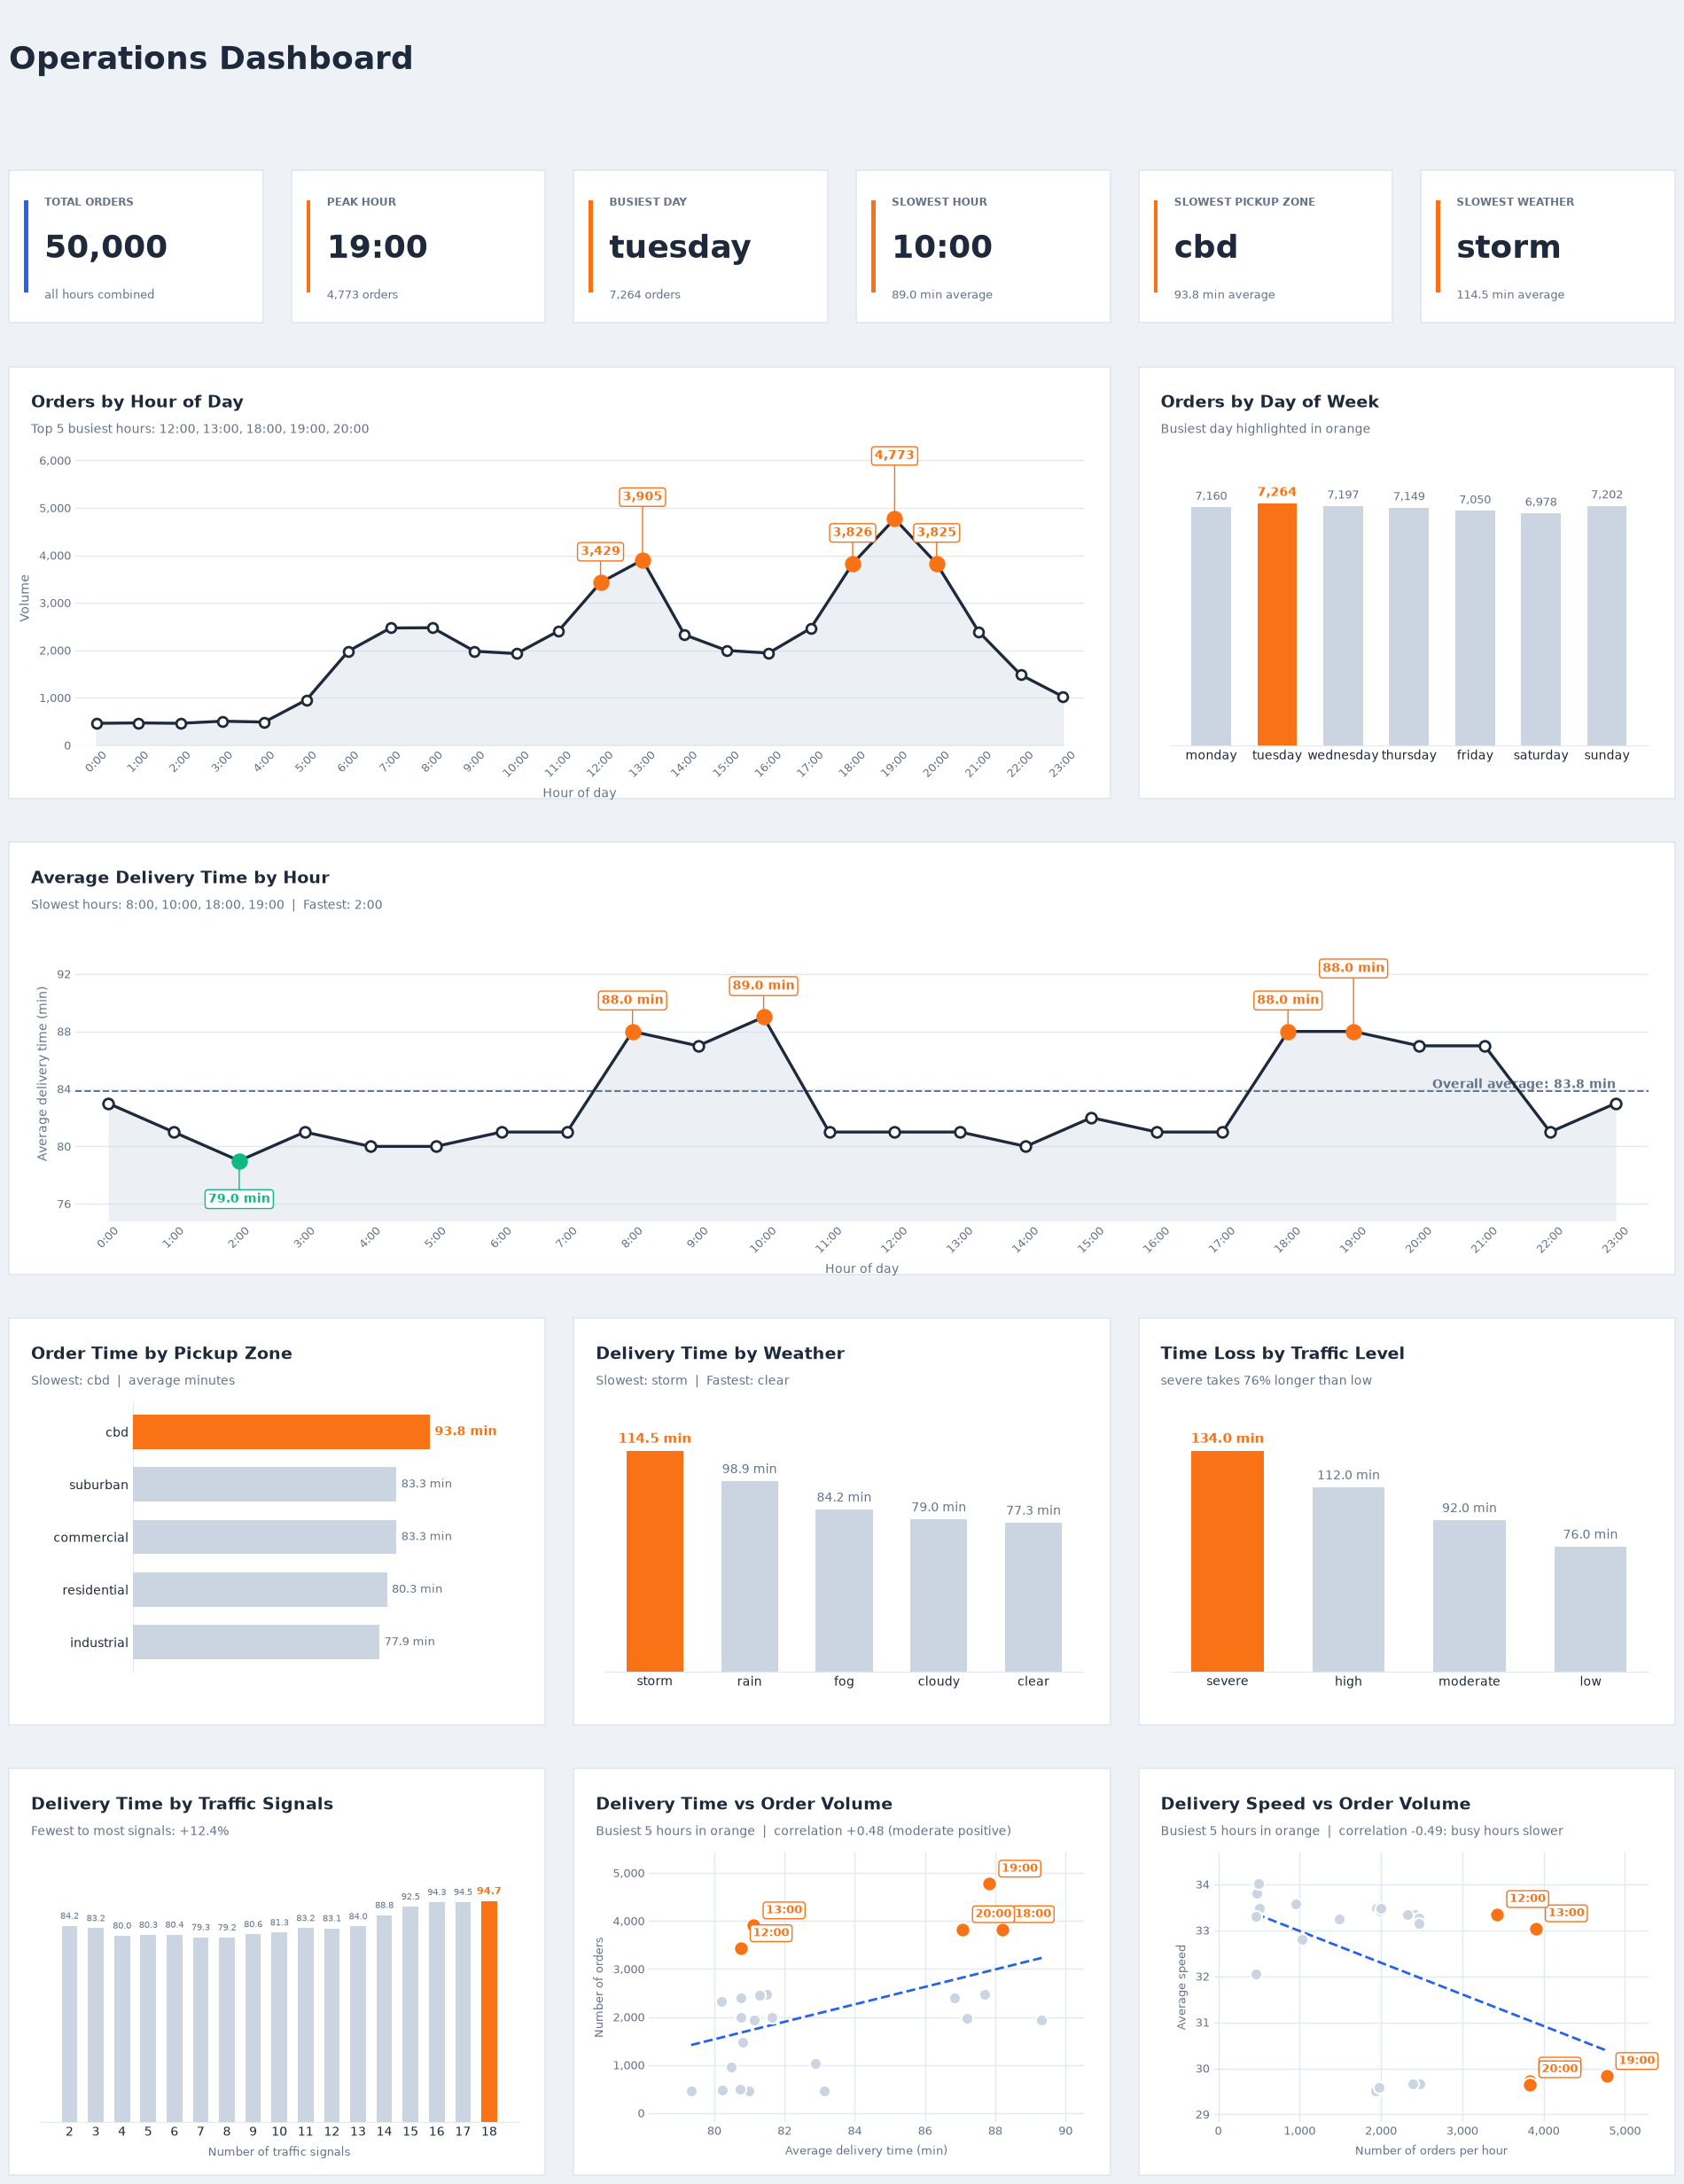

In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib.patches import Rectangle

# ---------------- Palette ----------------
BASE  = "#CBD5E1"
PEAK  = "#F97316"
GOOD  = "#10B981"
TREND = "#2563EB"
LINE  = "#1E293B"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"
BG    = "#EEF2F7"
CARD  = "#FFFFFF"
DARK  = "#0F172A"

N_PEAK = 5    # busiest hours to highlight
N_SLOW = 4    # slowest hours to highlight
fmt_int = FuncFormatter(lambda v, _: f"{v:,.0f}")

# ---------------- Data prep ----------------
bh     = busy_hours.sort_values("order_hour").reset_index(drop=True)
bh_h   = bh["order_hour"]
bh_n   = bh["count"]
bh_t   = bh["avg_del_time"]
bh_pk  = (bh_n >= bh_n.nlargest(N_PEAK).min()).values

dt     = del_avg_time.sort_values("order_hour").reset_index(drop=True)
dt_h   = dt["order_hour"]
dt_v   = dt["avg_time"]
overall = (dt_v * dt["count"]).sum() / dt["count"].sum()
dt_slow = (dt_v >= dt_v.nlargest(N_SLOW).min()).values
i_fast  = int(dt_v.values.argmin())

days  = orders_per_day["day_of_week"].astype(str)
d_cnt = orders_per_day["count"]

zones = pickup_zone_time.sort_values("order_time_taken", ascending=False).reset_index(drop=True)
wx    = weather_conditions.sort_values("avg_time", ascending=False).reset_index(drop=True)

tl = time_loss_traffic.copy()
order = ["Low", "Medium", "High", "Jam"]
if set(order) == set(tl["traffic_level"].str.title()):
    tl["traffic_level"] = tl["traffic_level"].str.title()
    tl = tl.set_index("traffic_level").loc[order].reset_index()
tl_vals = tl["time_taken"]
tl_w, tl_b = int(tl_vals.values.argmax()), int(tl_vals.values.argmin())
tl_extra = (tl_vals.iloc[tl_w] - tl_vals.iloc[tl_b]) / tl_vals.iloc[tl_b] * 100

sig = traffic_signals.sort_values("number_of_signals").reset_index(drop=True)

sp   = speed_per_hour.reset_index(drop=True)
sp_x, sp_y = sp["volume"], sp["avg_speed"]
sp_pk = (sp_x >= sp_x.nlargest(N_PEAK).min()).values

# ---------------- Figure + grid ----------------
W, H = 20, 26
fig = plt.figure(figsize=(W, H))
fig.patch.set_facecolor(BG)
gs = fig.add_gridspec(5, 12, height_ratios=[1.2, 3.4, 3.4, 3.2, 3.2],
                      hspace=0.12, wspace=0.25,
                      left=0.03, right=0.97, top=0.90, bottom=0.03)

# ---------------- Helpers ----------------
def card(ax, grid=None):
    ax.set_facecolor(CARD)
    ax.set_axisbelow(True)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=1, zorder=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0, labelsize=9, colors=MUTED)

def panel(spec, l=0.55, b=0.6, r=0.3, t=0.95):
    """White card filling a grid cell; chart placed inside with margins in inches."""
    box = spec.get_position(fig)
    bg = fig.add_axes(box.bounds, zorder=-1)
    bg.set_facecolor(CARD)
    bg.set_xticks([]); bg.set_yticks([])
    for s in bg.spines.values():
        s.set_color(GRID); s.set_linewidth(1.2)
    ax = fig.add_axes([box.x0 + l / W, box.y0 + b / H,
                       box.width - (l + r) / W, box.height - (b + t) / H])
    ax._l = l
    card(ax)
    return ax

def heading(ax, title, sub=None):
    x = -(ax._l - 0.25) / (ax.get_position().width * W)
    ax.annotate(title, xy=(x, 1), xycoords="axes fraction",
                xytext=(0, 32 if sub else 14), textcoords="offset points",
                fontsize=13.5, fontweight="bold", color=TEXT, ha="left", va="bottom")
    if sub:
        ax.annotate(sub, xy=(x, 1), xycoords="axes fraction",
                    xytext=(0, 12), textcoords="offset points",
                    fontsize=10, color=MUTED, ha="left", va="bottom")

def bar_panel(ax, labels, values, hi, fmt="{:.1f} min", horizontal=False, fs=10):
    labels = list(labels)
    colors = [PEAK if i == hi else BASE for i in range(len(values))]
    if horizontal:
        bars = ax.barh(labels, values, color=colors, height=0.65, zorder=3)
        ax.invert_yaxis()
        ax.set_xlim(0, values.max() * 1.3)
        ax.xaxis.set_visible(False)
        ax.spines["left"].set_visible(True)
        ax.spines["left"].set_color(GRID)
        ax.tick_params(axis="y", labelsize=10, colors=TEXT)
    else:
        bars = ax.bar(labels, values, color=colors, width=0.6, zorder=3)
        ax.set_ylim(0, values.max() * 1.22)
        ax.yaxis.set_visible(False)
        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_color(GRID)
        ax.tick_params(axis="x", labelsize=10, colors=TEXT)
    t = ax.bar_label(bars, labels=[fmt.format(v) for v in values],
                     padding=4, fontsize=fs, color=MUTED)
    t[hi].set_color(PEAK)
    t[hi].set_fontweight("bold")
    t[hi].set_fontsize(fs + 1)

def stagger_labels(ax, xs, ys, mask, fmt, color=PEAK):
    """Labels for highlighted points; consecutive hours alternate height so they never touch."""
    pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, linewidth=1)
    level, prev = 0, None
    for h, v, m in zip(xs, ys, mask):
        if not m:
            continue
        level = level + 1 if (prev is not None and h - prev == 1) else 0
        prev = h
        up = 20 + (level % 2) * 26
        ax.annotate(fmt.format(v), (h, v), xytext=(0, up), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10, fontweight="bold",
                    color=color, bbox=pill, zorder=6,
                    arrowprops=dict(arrowstyle="-", color=color, linewidth=1,
                                    shrinkA=0, shrinkB=6))

def scatter_panel(ax, x, y, hrs, mask):
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, slope * xs + intercept, color=TREND, linestyle="--", linewidth=2, zorder=2)
    ax.scatter(x[~mask], y[~mask], s=90, color=BASE, edgecolor="white", linewidth=1.5, zorder=3)
    ax.scatter(x[mask], y[mask], s=140, color=PEAK, edgecolor="white", linewidth=1.5, zorder=4)
    pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=PEAK, linewidth=1)
    for h, xi, yi, p in zip(hrs, x, y, mask):
        if p:
            ax.annotate(f"{h}:00", (xi, yi), xytext=(10, 10), textcoords="offset points",
                        fontsize=9, fontweight="bold", color=PEAK, bbox=pill, zorder=6)
    px = (x.max() - x.min()) * 0.12 or 1
    py = (y.max() - y.min()) * 0.15 or 1
    ax.set_xlim(x.min() - px, x.max() + px)
    ax.set_ylim(y.min() - py, y.max() + py)
    ax.grid(color=GRID, linewidth=1, zorder=0)
    return np.corrcoef(x, y)[0, 1]

def kpi_card(spec, label, value, sub, accent=PEAK):
    box = spec.get_position(fig)
    ax = fig.add_axes(box.bounds)
    ax.set_facecolor(CARD)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color(GRID); s.set_linewidth(1.2)
    ax.add_patch(Rectangle((0.06, 0.2), 0.016, 0.6, transform=ax.transAxes,
                           color=accent, linewidth=0))
    value = str(value)
    n = len(value)
    size = 26 if n <= 7 else 20 if n <= 10 else 15 if n <= 14 else 12
    ax.text(0.14, 0.82, label.upper(), transform=ax.transAxes,
            fontsize=8.5, color=MUTED, va="top", fontweight="bold")
    ax.text(0.14, 0.48, value, transform=ax.transAxes,
            fontsize=size, fontweight="bold", color=TEXT, va="center")
    ax.text(0.14, 0.14, sub, transform=ax.transAxes,
            fontsize=9.5, color=MUTED, va="bottom")

# ---------------- Header ----------------
hdr = fig.add_axes([0.03, 0.925, 0.94, 0.045])
hdr.set_facecolor(BG)
hdr.set_xticks([])
hdr.set_yticks([])

for s in hdr.spines.values():
    s.set_visible(False)

hdr.text(
    0.0, 0.5,
    "Operations Dashboard",
    transform=hdr.transAxes,
    fontsize=26,
    fontweight="bold",
    color=TEXT,
    va="center",
    ha="left"
)

# ---------------- KPI strip ----------------
slow_i = int(dt_v.values.argmax())
kpis = [
    ("Total orders", f"{bh_n.sum():,.0f}", "all hours combined", TREND),
    ("Peak hour", f"{bh_h[bh_n.idxmax()]}:00", f"{bh_n.max():,.0f} orders", PEAK),
    ("Busiest day", days[d_cnt.idxmax()], f"{d_cnt.max():,.0f} orders", PEAK),
    ("Slowest hour", f"{dt_h.iloc[slow_i]}:00", f"{dt_v.iloc[slow_i]:.1f} min average", PEAK),
    ("Slowest pickup zone", str(zones["pickup_zone"].iloc[0]),
        f"{zones['order_time_taken'].iloc[0]:.1f} min average", PEAK),
    ("Slowest weather", str(wx["weather"].iloc[0]),
        f"{wx['avg_time'].iloc[0]:.1f} min average", PEAK),
]
for i, (lab, val, sub, acc) in enumerate(kpis):
    kpi_card(gs[0, 2 * i: 2 * i + 2], lab, val, sub, acc)

# ---------------- 1. Orders by hour ----------------
ax = panel(gs[1, 0:8], l=0.75)
card(ax, grid="y")
ax.fill_between(bh_h, bh_n, color=BASE, alpha=0.35, zorder=1)
ax.plot(bh_h, bh_n, color=LINE, linewidth=2.4, zorder=3)
ax.scatter(bh_h[~bh_pk], bh_n[~bh_pk], s=60, color="white", edgecolor=LINE, linewidth=2, zorder=4)
ax.scatter(bh_h[bh_pk], bh_n[bh_pk], s=150, color=PEAK, zorder=5)
stagger_labels(ax, bh_h, bh_n, bh_pk, "{:,.0f}")
ax.set_ylim(0, bh_n.max() * 1.3)
ax.set_xlim(bh_h.min() - 0.5, bh_h.max() + 0.5)
ax.set_xticks(np.arange(0, 24))
ax.set_xticklabels([f"{h}:00" for h in range(24)], rotation=45, fontsize=9, color=MUTED)
ax.set_xlabel("Hour of day", fontsize=10, color=MUTED, labelpad=6)
ax.set_ylabel("Volume", fontsize=10, color=MUTED, labelpad=6)
ax.yaxis.set_major_formatter(fmt_int)
heading(ax, "Orders by Hour of Day",
        f"Top {N_PEAK} busiest hours: " + ", ".join(f"{h}:00" for h in bh_h[bh_pk]))

# ---------------- 2. Orders by day ----------------
ax = panel(gs[1, 8:12], l=0.35)
bar_panel(ax, days, d_cnt, int(d_cnt.values.argmax()), fmt="{:,.0f}", fs=9)
heading(ax, "Orders by Day of Week", "Busiest day highlighted in orange")

# ---------------- 3. Average delivery time by hour (full width) ----------------
ax = panel(gs[2, 0:12], l=0.75)
card(ax, grid="y")
pad  = (dt_v.max() - dt_v.min()) * 0.35 or 1
y_lo = dt_v.min() - pad * 1.2
y_hi = dt_v.max() + pad * 1.8
ax.set_ylim(y_lo, y_hi)
ax.fill_between(dt_h, dt_v, y_lo, color=BASE, alpha=0.35, linewidth=0, zorder=1)
ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1.4, zorder=2)
ax.text(dt_h.iloc[-1], overall, f"Overall average: {overall:.1f} min",
        ha="right", va="bottom", fontsize=10, color=MUTED, fontweight="bold")
ax.plot(dt_h, dt_v, color=LINE, linewidth=2.4, zorder=3)
ax.scatter(dt_h[~dt_slow], dt_v[~dt_slow], s=70, color="white", edgecolor=LINE, linewidth=2, zorder=4)
ax.scatter(dt_h[dt_slow], dt_v[dt_slow], s=150, color=PEAK, zorder=5)
ax.scatter(dt_h.iloc[i_fast], dt_v.iloc[i_fast], s=150, color=GOOD, zorder=5)
stagger_labels(ax, dt_h, dt_v, dt_slow, "{:.1f} min")
ax.annotate(f"{dt_v.iloc[i_fast]:.1f} min", (dt_h.iloc[i_fast], dt_v.iloc[i_fast]),
            xytext=(0, -26), textcoords="offset points", ha="center", va="top",
            fontsize=10, fontweight="bold", color=GOOD,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=GOOD, linewidth=1),
            zorder=6, arrowprops=dict(arrowstyle="-", color=GOOD, linewidth=1, shrinkA=0, shrinkB=6))
ax.set_xlim(dt_h.min() - 0.5, dt_h.max() + 0.5)
ax.set_xticks(np.arange(0, 24))
ax.set_xticklabels([f"{h}:00" for h in range(24)], rotation=45, fontsize=9, color=MUTED)
ax.set_xlabel("Hour of day", fontsize=10, color=MUTED, labelpad=6)
ax.set_ylabel("Average delivery time (min)", fontsize=10, color=MUTED, labelpad=6)
ax.yaxis.set_major_locator(MaxNLocator(6))
heading(ax, "Average Delivery Time by Hour",
        "Slowest hours: " + ", ".join(f"{h}:00" for h in dt_h[dt_slow]) +
        f"  |  Fastest: {dt_h.iloc[i_fast]}:00")

# ---------------- 4. Pickup zone ----------------
ax = panel(gs[3, 0:4], l=1.4)
bar_panel(ax, zones["pickup_zone"].astype(str), zones["order_time_taken"], 0,
          horizontal=True, fs=9)
heading(ax, "Order Time by Pickup Zone",
        f"Slowest: {zones['pickup_zone'].iloc[0]}  |  average minutes")

# ---------------- 5. Weather ----------------
ax = panel(gs[3, 4:8], l=0.35)
bar_panel(ax, wx["weather"].astype(str), wx["avg_time"], 0)
heading(ax, "Delivery Time by Weather",
        f"Slowest: {wx['weather'].iloc[0]}  |  Fastest: {wx['weather'].iloc[-1]}")

# ---------------- 6. Traffic level ----------------
ax = panel(gs[3, 8:12], l=0.35)
bar_panel(ax, tl["traffic_level"].astype(str), tl_vals, tl_w)
heading(ax, "Time Loss by Traffic Level",
        f"{tl['traffic_level'].iloc[tl_w]} takes {tl_extra:.0f}% longer than "
        f"{tl['traffic_level'].iloc[tl_b]}")

# ---------------- 7. Traffic signals ----------------
ax = panel(gs[4, 0:4], l=0.35)
vals = sig["time_taken"]
wi = int(vals.values.argmax())
bar_panel(ax, sig["number_of_signals"].astype(int).astype(str), vals, wi,
          fmt="{:.1f} min" if len(vals) <= 5 else "{:.1f}",
          fs=9 if len(vals) <= 8 else 7)
ax.set_xlabel("Number of traffic signals", fontsize=9, color=MUTED, labelpad=6)
change = (vals.iloc[-1] - vals.iloc[0]) / vals.iloc[0] * 100
heading(ax, "Delivery Time by Traffic Signals",
        f"Fewest to most signals: {change:+.1f}%")

# ---------------- 8. Delivery time vs volume ----------------
ax = panel(gs[4, 4:8], l=0.85)
corr = scatter_panel(ax, bh_t, bh_n, bh_h, bh_pk)
strength  = "strong" if abs(corr) >= 0.7 else "moderate" if abs(corr) >= 0.4 else "weak"
direction = "positive" if corr > 0 else "negative"
ax.set_xlabel("Average delivery time (min)", fontsize=9, color=MUTED, labelpad=6)
ax.set_ylabel("Number of orders", fontsize=9, color=MUTED, labelpad=6)
ax.yaxis.set_major_formatter(fmt_int)
heading(ax, "Delivery Time vs Order Volume",
        f"Busiest {N_PEAK} hours in orange  |  correlation {corr:+.2f} ({strength} {direction})")

# ---------------- 9. Speed vs volume ----------------
ax = panel(gs[4, 8:12], l=0.85)
corr2 = scatter_panel(ax, sp_x, sp_y, sp["order_hour"], sp_pk)
strength2 = "strong" if abs(corr2) >= 0.7 else "moderate" if abs(corr2) >= 0.4 else "weak"
meaning   = (("busy hours slower" if corr2 < 0 else "busy hours faster")
             if abs(corr2) >= 0.4 else "little link")
ax.xaxis.set_major_formatter(fmt_int)
ax.set_xlabel("Number of orders per hour", fontsize=9, color=MUTED, labelpad=6)
ax.set_ylabel("Average speed", fontsize=9, color=MUTED, labelpad=6)   # add the unit, e.g. (km/h)
heading(ax, "Delivery Speed vs Order Volume",
        f"Busiest {N_PEAK} hours in orange  |  correlation {corr2:+.2f}: {meaning}")

# ---------------- Save + show ----------------
os.makedirs("../images", exist_ok=True)
fig.savefig("../images/delivery_dashboard2.png", dpi=180, bbox_inches="tight", facecolor=BG)
plt.show()